# Emprendedores inscritos en la Secretaría de Desarrollo Económico de Facatativá
## Análisis estadístico, limpieza de datos y análisis de texto con sentimientos
## Nota. El presente Notebook es amplio, no solo por su codigo si no tambien por sus comentarios que acompañan a cada linea ya que en la instrucción del documento, no se podia generar un infrome en formato Pdf, es por eso que dentro del mismo noebook, existen comentarios bastantes largos y necesarios a comprender.

|  |  |
|--|--|
| **Autor** | Kevin Esteban Diaz PInilla |
| **Fecha** | 14 de noviembre de 2026 |
| **Programa** | Especialización en Analítica y Ciencia de Datos, Universidad de Cundinamarca |
| **Fuente de datos** | Archivo de Excel *"Emprendedores inscritos – Secretaría de Desarrollo Económico, Alcaldía de Facatativá"* (descargado el 14/11/2026) |

---

### Estructura: dos partes separadas

| | Contenido | Resultado |
|---|---|---|
| **PARTE 1** | Carga, exploración, **limpieza y transformación** de los datos | Guarda la tabla limpia en `emprendedores_limpio.csv` |
| **PARTE 2** | **Análisis estadístico**, visualización, análisis de texto y sentimientos, conclusiones | Lee la tabla limpia y no modifica los datos originales |



### Cómo leer este cuaderno 

Este documento Mezcla dos tipos de celdas:

* **Celdas de texto (como esta):** explican con palabras sencillas *qué* se hace, *por qué* se hace y *con qué herramienta*. 
* **Celdas de código (con fondo gris):** son las instrucciones que el computador ejecuta. Debajo de cada una aparece su resultado (una tabla, un número o un gráfico). Las líneas que empiezan con `#` son **comentarios**: no se ejecutan, solo explican el código a quien lo lee.

Cada paso sigue siempre el mismo orden: **1. qué se hace → 2. por qué → 3. herramienta → 4. código y resultado (siempre mostrando el ANTES y el DESPUÉS) → 5. lectura del resultado.**

## 1. Objetivos del análisis y contexto

### Contexto
La Secretaría de Desarrollo Económico de la Alcaldía de Facatativá (Cundinamarca) mantiene un registro de **personas emprendedoras** del municipio. Cada fila del archivo es **una persona inscrita** con su emprendimiento. El formulario recoge datos personales (edad, género, formación), del negocio (nombre, descripción, línea económica, fecha de creación, empleados) y de su formalización (Cámara de Comercio, RUT, página web).

Conocer *quiénes son* estos emprendedores y *qué tan formalizados y consolidados están* ayuda a la Alcaldía a decidir **dónde enfocar capacitaciones, apoyos y programas de formalización**.

### Objetivo general
Describir el perfil de los emprendedores inscritos y su nivel de formalización y madurez, y analizar los textos con que describen sus negocios, para **respaldar decisiones de política de fomento al emprendimiento**.

### Objetivos específicos
1. **Explorar** el archivo: tamaño, tipos de datos, valores faltantes y estadística descriptiva básica.
2. **Limpiar y transformar** los datos (unificar escrituras distintas de una misma respuesta, tratar valores atípicos, faltantes y duplicados) y **crear variables nuevas** a partir de las existentes.
3. **Analizar y visualizar** el perfil de los emprendedores, su formalización, empleo y madurez, comparando antes y después de la limpieza.
4. **Analizar los textos** (descripciones de la actividad): limpiarlos, convertirlos en datos numéricos, encontrar términos y expresiones frecuentes y **medir el sentimiento**.
5. **Concluir** con hallazgos, implicaciones y recomendaciones prácticas.

### Variables creadas
El archivo **no contiene ingresos ni ventas**. En lugar de inventar una cifra de ingresos (que no tendría respaldo), se tomo la decisión de construir **indicadores verificables a partir de los propios datos**: antigüedad del negocio, índice de formalización, tamaño por número de empleados y un *índice de madurez* que los combina. Estas variables "nutren" el análisis estadístico sin salirse de lo que realmente dicen los datos.

### Preparación del entorno (Parte 1): herramientas que se van a utilizar

**1. Qué se hace:** cargar las librerías (paquetes de código ya hechos por la comunidad) que se necesitan.

**2. Por qué:** estas librerías están probadas y son el estándar en ciencia de datos.

**3. Herramientas:**

| Librería | Para qué sirve en este cuaderno |
|---|---|
| `pandas` | Manejar tablas (como Excel, pero programable): leer, filtrar, agrupar, calcular. |
| `numpy` | Cálculos numéricos. |
| `matplotlib` | Dibujar los gráficos. |
| `scipy` | Pruebas estadísticas (para saber si una diferencia es real o casual). |
| `re` y `unicodedata` | Limpiar texto (quitar símbolos, URLs, tildes). Vienen incluidas con Python. |

In [51]:
# --- Librerías generales ---
import re                      # expresiones regulares: buscar/reemplazar patrones en texto
import unicodedata             # manejo de tildes y caracteres especiales
import warnings                # para ocultar avisos que no aportan al lector
import numpy as np             # cálculo numérico
import pandas as pd            # tablas de datos
import matplotlib.pyplot as plt   # gráficos
from scipy import stats        # pruebas estadísticas

warnings.filterwarnings("ignore")

# --- Estilo simple y uniforme para todos los gráficos ---
plt.rcParams.update({
    "figure.figsize": (8, 4.5),     # tamaño por defecto
    "axes.grid": True,              # cuadrícula suave para leer valores
    "grid.alpha": 0.3,
    "axes.spines.top": False,       # quitamos bordes innecesarios
    "axes.spines.right": False,
    "font.size": 10,
})
AZUL, NARANJA, GRIS = "#2E6F9E", "#E07B39", "#8C8C8C"   # paleta sobria: azul = principal, naranja = comparación
pd.set_option("display.max_colwidth", 90)               # mostrar textos largos completos en las tablas
pd.set_option("display.width", 200)

def etiquetar(ax):
    """Escribe el valor encima de cada barra para no tener que adivinarlo en el eje."""
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fontsize=9, padding=2)

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


# PARTE 1 · Carga, exploración, limpieza y transformación

> **Objetivo:** dejar los datos **ordenados y confiables**. Aquí no se saca ninguna conclusión del negocio; solo se prepara la materia prima. Al final se guarda `emprendedores_limpio.csv`, que es lo único que usa la Parte 2.
>
> **Regla:** cada paso muestra el **ANTES** (cómo venían los datos) y el **DESPUÉS** (cómo quedaron), para que se vea el efecto de cada decisión.

## 2. Carga y exploración inicial

Antes de limpiar o analizar nada hay que **conocer los datos tal como vienen**. 

### 2.1 Lectura del archivo

**1. Qué se hace:** leer el archivo de Excel y guardarlo en una tabla llamada `df_original`.

**2. Por qué:** `df_original` será la **copia intocable** del archivo. Todo lo que se realiza después se hace sobre otra copia (`df`), de modo que siempre se pueda comparar "antes" y "después" y repetir el proceso desde cero.

**3. Herramienta:** `pandas` (`pd.read_excel`).



In [52]:
ARCHIVO = "EMPRENDEDORES_INSCRITOS_SECRETARIA_DE_DESARROLLO_ECONÓMICO_-ALCALDÍA_DE_FACATATIVÁ_20261114.xlsx"   

df_original = pd.read_excel(ARCHIVO)                 # lectura del Excel (hoja "Data")

# Guardar los nombres largos originales para poder mostrar la equivalencia
nombres_originales = list(df_original.columns)

# Nombres cortos, en el mismo orden que las columnas del archivo
nombres_cortos = [
    "item", "tipo_id", "lugar_nacimiento", "edad", "genero", "formacion",
    "municipio_res", "zona_res", "poblacion", "zona_emp", "nombre",
    "fecha_creacion", "modalidad", "descripcion", "linea_economica",
    "camara_comercio", "rut", "empleados", "pagina_web",
]
df_original.columns = nombres_cortos

# Tabla de equivalencias (nombre corto -> pregunta original del formulario)
equivalencias = pd.DataFrame({
    "nombre_corto": nombres_cortos,
    "pregunta_original": [re.sub(r"\s+", " ", n).strip() for n in nombres_originales],
})
equivalencias

,nombre_corto,pregunta_original
0,item,Item
1,tipo_id,Tipo de identificación:
2,lugar_nacimiento,Lugar de nacimiento:
3,edad,Edad:
4,genero,Género:
5,formacion,Nivel de formación:
6,municipio_res,Municipio de Residencia:
7,zona_res,Zona de residencia:
8,poblacion,¿Pertenece a alguna población vulnerable o diferencial?
9,zona_emp,Zona donde se Desarrolla el Emprendimiento


### 2.2 Dimensiones, tipos de datos y valores faltantes

**1. Qué se hace:** responder cuatro preguntas básicas: ¿cuántas filas y columnas hay?, ¿de qué **tipo** es cada columna (número, texto, fecha)?, ¿cuántos **valores faltantes** tiene?, ¿cuántos valores **distintos** tiene?

**2. Por qué:** los tipos determinan qué cálculos tienen sentido (no se puede promediar un texto). Los faltantes y la cantidad de valores distintos son la primera señal de problemas de calidad: si el *género* tiene 5 valores distintos pero en la realidad solo hay 2 categorías, hay respuestas escritas de formas diferentes.

**3. Herramienta:** `pandas` (`.shape`, `.dtypes`, `.isna()`, `.nunique()`).

In [53]:
filas, columnas = df_original.shape
print(f"El archivo tiene {filas} emprendedores (filas) y {columnas} variables (columnas).\n")

# Resumen de calidad: tipo, faltantes y valores distintos por columna
calidad = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "faltantes": df_original.isna().sum(),
    "% faltantes": (df_original.isna().mean() * 100).round(1),
    "valores_distintos": df_original.nunique(),
})
calidad

El archivo tiene 298 emprendedores (filas) y 19 variables (columnas).



,tipo,faltantes,% faltantes,valores_distintos
item,int64,0,0.0,297
tipo_id,str,0,0.0,8
lugar_nacimiento,str,0,0.0,139
edad,int64,0,0.0,58
genero,str,0,0.0,5
formacion,str,0,0.0,43
municipio_res,str,0,0.0,9
zona_res,str,0,0.0,3
poblacion,str,0,0.0,13
zona_emp,str,1,0.3,4


**5. Lectura del resultado.** El archivo está **casi completo**: solo hay 3 celdas vacías en total (1 en la zona del emprendimiento y 2 en la línea económica). El problema de calidad **no son los faltantes sino la variedad de escrituras**: se debe hacer enfasis en la columna `valores_distintos`: *género* tiene 5 valores (debería tener 2), *formación* tiene 43 y *línea económica* tiene 80. Eso confirma que habrá que unificar categorías.

### 2.3 Estadística descriptiva de las variables numéricas

**1. Qué se hace:** calcular las **medidas de tendencia central** (¿cuál es el valor "típico"?: media, mediana, moda) y de **dispersión** (¿qué tanto varían los datos?: desviación estándar, rango, coeficiente de variación) para `edad` y `empleados`. Añadimos la **asimetría**, que indica si los datos se "estiran" hacia valores altos (positiva) o bajos (negativa).

**2. Por qué:** un solo número (el promedio) puede engañar. Por ejemplo, si la media de empleados es 0,4 pero la mediana es 0, significa que la mayoría **no** tiene empleados y unos pocos negocios tienden a aumentar el promedio hacia arriba.

**3. Herramienta:** `pandas` y `scipy`.

In [54]:
def resumen_numerico(serie):
    """Devuelve las principales medidas descriptivas de una columna numérica."""
    return {
        "n": serie.count(),
        "media": serie.mean(),
        "mediana": serie.median(),
        "moda": serie.mode().iloc[0],
        "desv. estándar": serie.std(),
        "mínimo": serie.min(),
        "máximo": serie.max(),
        "coef. variación (%)": serie.std() / serie.mean() * 100,   # dispersión relativa a la media
        "asimetría": stats.skew(serie),
    }

tabla_desc = pd.DataFrame({
    "edad (años)": resumen_numerico(df_original["edad"]),
    "empleados (n.º)": resumen_numerico(df_original["empleados"]),
}).round(2)
tabla_desc

,edad (años),empleados (n.º)
n,298.00,298.00
media,44.14,0.38
mediana,42.50,0.00
moda,34.00,0.00
desv. estándar,13.15,0.91
mínimo,17.00,0.00
máximo,76.00,5.00
coef. variación (%),29.79,238.09
asimetría,0.26,2.87


### Interpretación de la estadística descriptiva (edad y empleados)

**Edad (años)**

- **Tamaño de la muestra (n = 298):** se analizaron los 298 emprendedores y ninguno tiene la edad vacía, así que los resultados usan todos los datos.
- **Tendencia central:** la **media es 44,1 años** y la **mediana es 42,5**. Como son valores cercanos, no hay edades extremas que distorsionen el promedio. Es decir, la persona emprendedora **típica tiene entre 42 y 44 años**.
- **Moda (34 años):** es la edad que más se repite, y es menor que la media. Indica que hay un grupo importante de emprendedores más jóvenes, alrededor de los 34 años.
- **Dispersión:** la desviación estándar de **13,15 años** significa que, en general, las edades se alejan del promedio unos 13 años hacia arriba o hacia abajo. El **coeficiente de variación (29,8 %)** indica una dispersión **moderada**: hay variedad de edades, pero no extrema.
- **Rango:** va de **17 a 76 años**, es decir, participan desde adolescentes hasta personas adultas mayores. Un emprendedor de 17 años es un caso para revisar (menor de edad), aunque es un dato posible.
- **Forma de la distribución:** la **asimetría de 0,26** es muy cercana a cero, así que la distribución es **casi simétrica**: hay un equilibrio entre personas más jóvenes y mayores respecto a la edad central.

**Empleados (n.º)**

- **Tendencia central:** la **mediana y la moda son 0**, mientras que la media es 0,38. Esto significa que **la mayoría de los emprendimientos no tiene empleados**: son negocios **unipersonales o familiares**.
- **Por qué la media engaña:** la media (0,38) es mayor que la mediana porque **unos pocos negocios tienen hasta 5 empleados** y "jalan" el promedio hacia arriba. Por eso, en esta variable es más fiel hablar del **porcentaje de negocios con empleados** que del promedio.
- **Dispersión:** la desviación estándar (0,91) es **más del doble de la media**, y el **coeficiente de variación (238 %)** es muy alto. Esto indica que los datos son **muy heterogéneos**: casi todos tienen 0 y unos pocos tienen valores altos. Para este tipo de variable, el coeficiente de variación **no sirve como medida de dispersión confiable**, porque la media está cerca de cero.
- **Rango:** va de **0 a 5 empleados**; ningún emprendimiento supera los cinco.
- **Forma de la distribución:** la **asimetría de 2,87** es **fuertemente positiva**, es decir, los datos se concentran en valores bajos (0) y tienen una "cola larga" hacia valores altos.

**Conclusión para la toma de decisiones**

- El perfil de edad es **estable y equilibrado**: los programas de apoyo no

### 2.4 Distribución de las variables numéricas

**1. Qué se hace:** dibujar un **histograma** de la edad (cuántas personas hay en cada rango de edad) con líneas que marcan la media y la mediana, un **diagrama de caja** (*boxplot*: la caja contiene el 50 % central de los datos y los puntos aislados son posibles valores atípicos) y un gráfico de barras con el número de empleados.

**2. Por qué:** los gráficos muestran la *forma* de los datos, algo que una tabla de números no deja ver.

**3. Herramienta:** `matplotlib`.

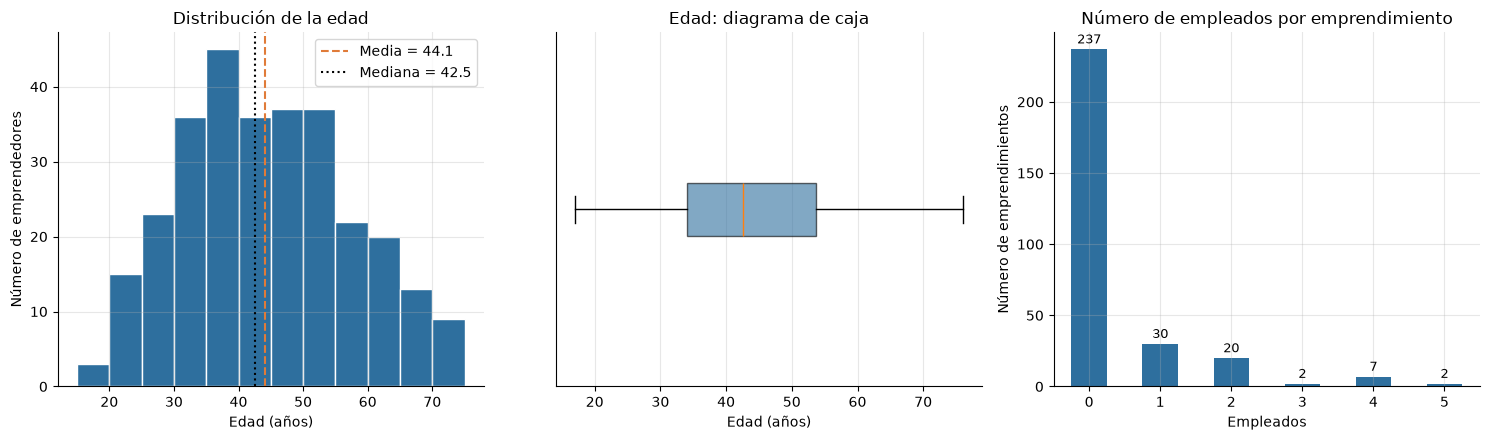

In [55]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

# (a) Histograma de edad
ejes[0].hist(df_original["edad"], bins=range(15, 80, 5), color=AZUL, edgecolor="white")
ejes[0].axvline(df_original["edad"].mean(), color=NARANJA, linestyle="--", label=f"Media = {df_original['edad'].mean():.1f}")
ejes[0].axvline(df_original["edad"].median(), color="black", linestyle=":", label=f"Mediana = {df_original['edad'].median():.1f}")
ejes[0].set_title("Distribución de la edad")
ejes[0].set_xlabel("Edad (años)"); ejes[0].set_ylabel("Número de emprendedores")
ejes[0].legend()

# (b) Diagrama de caja de la edad
ejes[1].boxplot(df_original["edad"], vert=False, patch_artist=True, boxprops=dict(facecolor=AZUL, alpha=0.6))
ejes[1].set_title("Edad: diagrama de caja")
ejes[1].set_xlabel("Edad (años)"); ejes[1].set_yticks([])

# (c) Empleados
conteo_emp = df_original["empleados"].value_counts().sort_index()
conteo_emp.plot.bar(ax=ejes[2], color=AZUL, rot=0)
etiquetar(ejes[2])
ejes[2].set_title("Número de empleados por emprendimiento")
ejes[2].set_xlabel("Empleados"); ejes[2].set_ylabel("Número de emprendimientos")

plt.tight_layout(); plt.show()

**5. Lectura del resultado.** Confirma los resultados anteriores

* **Edad:** el emprendedor típico tiene unos **43 años** (mediana 42,5; media 44,1). Los datos van de 17 a 76 años y son casi simétricos (asimetría 0,26): no hay edades extrañas. La dispersión es moderada (coeficiente de variación ≈ 30 %).
* **Empleados:** la **mediana es 0**: **la mayoría de los emprendimientos (cerca del 80 %) son unipersonales**. La media (0,38) queda por encima de la mediana porque unos pocos negocios tienen hasta 5 empleados (asimetría 2,87 = datos muy "estirados" hacia valores altos). Por eso, para empleados conviene hablar de **porcentaje con empleados** y no de promedio.

### 2.5 Exploración de las variables categóricas "tal como vienen"

**1. Qué se hace:** identificar cómo aparecen escritas las respuestas de algunas columnas de categorías (género, tipo de documento, línea económica, formación).

**2. Por qué:** es aquí donde se descubre el principal problema de calidad del archivo: **la misma respuesta escrita de muchas maneras** ("Femenino", "FEMENINO", "femenino"). Para un computador son valores distintos, y si no se corrige, los conteos y gráficos quedan **partidos y engañosos**. Esto justifica toda la sección 3.

**3. Herramienta:** `pandas` (`.value_counts()`).

In [56]:
print("GÉNERO (tal como viene):")
print(df_original["genero"].value_counts().to_string())

print("\nTIPO DE DOCUMENTO (tal como viene):")
print(df_original["tipo_id"].value_counts().to_string())

print("\nLÍNEA ECONÓMICA (tal como viene) – primeros 15 de", df_original["linea_economica"].nunique(), "valores distintos:")
print(df_original["linea_economica"].value_counts().head(15).to_string())

GÉNERO (tal como viene):
genero
Femenino     128
FEMENINO      85
Masculino     45
MASCULINO     38
femenino       2

TIPO DE DOCUMENTO (tal como viene):
tipo_id
Cédula de ciudadanía                     269
Cedula de ciudadanua                      10
Cedula de ciudadania                       8
PPT - Permiso por Protección Temporal      4
Cedula de ciudadanía                       3
CEdula de ciudadania                       2
Tarjeta de identidad:                      1
Caycedo Zuluaga                            1

LÍNEA ECONÓMICA (tal como viene) – primeros 15 de 80 valores distintos:
linea_economica
Alimentos        98
ARTESANIAS       29
MANUALIDADES     18
Artesanía        15
Textil           11
Artesanias        7
Comerciante       7
Servicios         7
Manualidades      6
TEXTIL            5
MANUALISTA        5
Manualista        5
COMERCIANTE       4
Manualidad        3
Nuevo Talento     3


**5. Lectura del resultado.** Este es el hallazgo central de la exploración: el género aparece como *Femenino, FEMENINO, femenino, Masculino, MASCULINO* (5 "categorías" para 2 realidades), el tipo de documento como *Cédula de ciudadanía, Cedula de ciudadanua, CEdula de ciudadania...*, y la línea económica mezcla *Artesanías, ARTESANIAS, Artesanía, Manualidades, Manualista...* Sin limpiar, cualquier gráfico mostraría barras fragmentadas.

### 2.6 Fechas: rango de creación de los emprendimientos

**1. Qué se hace:** ver cuál es la fecha de creación más antigua y la más reciente, y los años con más emprendimientos creados.

**2. Por qué:** las fechas imposibles (un negocio "creado" en el año 1905) son errores de digitación y distorsionarían cualquier cálculo de antigüedad.

In [57]:
print("Fecha de creación más antigua :", df_original["fecha_creacion"].min().date())
print("Fecha de creación más reciente:", df_original["fecha_creacion"].max().date())
print("\nLas 6 fechas más antiguas del archivo:")
print(df_original.nsmallest(6, "fecha_creacion")[["item", "nombre", "edad", "fecha_creacion"]].to_string(index=False))

Fecha de creación más antigua : 1905-07-16
Fecha de creación más reciente: 2025-09-19

Las 6 fechas más antiguas del archivo:
 item                       nombre  edad fecha_creacion
   73                   EBBY STORE    47     1905-07-16
   60                       APICAR    64     1970-02-01
   46 TALLER DE CARPINTERÍA TOLIMA    61     1984-01-01
  241             Arepas y postres    39     1985-09-01
  174                    Colibries    70     1991-08-05
  243                 OCEANO PIZZA    45     1994-04-04


## 3. Limpieza y transformación de los datos

**Principio de trabajo:** nunca se modifica el archivo original. Se tomo la decisión de crear una **copia de trabajo** (`df`) y, para cada variable que se limpia, se crea una **columna nueva** (por ejemplo `genero_limpio`) dejando la columna original al lado. Así se puede **comparar antes y después** y cualquier persona puede auditar cada decisión.

Sin embargo, **Cada decisión se justifica** en el texto que la acompaña.

### 3.1 Copia de trabajo y función de normalización de texto

**1. Qué se hace:** crear la copia `df` y una **función**  llamada `normalizar` que convierte cualquier texto a una forma estándar: sin espacios sobrantes, en minúsculas y sin tildes (conservando la ñ).

**2. Por qué:** "Cédula", "CEDULA " y "cedula" deben ser reconocidas como lo mismo. Pasar todo a minúsculas, sin tildes y sin espacios extra elimina las diferencias que no significan nada.

**3. Herramienta:** `re` y `unicodedata` (incluidas en Python).

In [58]:
df = df_original.copy()    # copia de trabajo: df_original queda intacto

def normalizar(texto):
    """Pone un texto en forma estándar: minúsculas, sin tildes, sin espacios repetidos."""
    if pd.isna(texto):                       # si el dato falta, se deja como faltante
        return np.nan
    t = str(texto).strip().lower()           # quitar espacios de los extremos y pasar a minúsculas
    t = t.replace("ñ", "§")                  # proteger la ñ (si no, perdería su "tilde" y cambiaría la palabra)
    t = "".join(c for c in unicodedata.normalize("NFD", t) if unicodedata.category(c) != "Mn")  # quitar tildes
    t = t.replace("§", "ñ")                  # devolver la ñ
    return re.sub(r"\s+", " ", t)            # varios espacios seguidos -> uno solo

# Prueba rápida para ver qué hace la función
for ejemplo in ["  FEMENINO ", "Cédula de ciudadanía", "DISEÑO   y  Confección"]:
    print(repr(ejemplo), "->", repr(normalizar(ejemplo)))

def mapa_antes_despues(original, limpia, max_ejemplos=4):
    """Tabla ANTES -> DESPUÉS: para cada categoría FINAL muestra cuántos registros tiene y
    cuántas escrituras ORIGINALES distintas se unificaron en ella (con ejemplos)."""
    tmp = pd.DataFrame({"final": df[limpia].astype(object).fillna("Sin dato"),
                        "orig": df[original].fillna("(vacío)").astype(str).str.replace(r"\s+", " ", regex=True).str.strip().str[:38]})
    tabla = tmp.groupby("final").agg(
        registros=("orig", "count"),
        escrituras_originales=("orig", "nunique"),
        ejemplos_de_como_venian=("orig", lambda s: " | ".join(s.value_counts().index[:max_ejemplos])),
    ).sort_values("registros", ascending=False)
    return tabla

def mostrar_antes_despues(original, limpia, titulo):
    """Imprime el resumen ANTES/DESPUÉS de una variable y la tabla de equivalencias."""
    print(f"{titulo}: ANTES = {df[original].nunique()} escrituras distintas  ->  DESPUÉS = {df[limpia].astype(object).fillna('Sin dato').nunique()} categorías")
    display(mapa_antes_despues(original, limpia))

# Función auxiliar: clasifica un texto según palabras clave (se usa en varias variables)
def clasificar(texto, reglas, defecto="Sin dato"):
    """Recorre las reglas en orden; si el texto contiene alguna palabra clave, devuelve esa categoría."""
    t = normalizar(texto)
    if pd.isna(t):
        return defecto
    for categoria, palabras_clave in reglas.items():
        if any(p in t for p in palabras_clave):
            return categoria
    return defecto

'  FEMENINO ' -> 'femenino'
'Cédula de ciudadanía' -> 'cedula de ciudadania'
'DISEÑO   y  Confección' -> 'diseño y confeccion'


### 3.2 Variables con pocas categorías: género, documento, municipio, zonas, modalidad y Sí/No

**1. Qué se hace:** unificar las escrituras de las variables simples.

**2. Por qué y decisiones tomadas:**

* **Género, modalidad, zona urbana/rural, Sí/No:** basta normalizar el texto; "SI", "Si" y "si" pasan a **"Sí"**.
* **Tipo de documento:** las variantes con errores de digitación ("Cedula de ciudadanua", "CEdula de ciudadania") se agrupan en **"Cédula de ciudadanía"**. Un registro trae un apellido ("Caycedo Zuluaga") en lugar de un tipo de documento: es un dato **mal ubicado** y no se puede adivinar cuál era, así que se marca **"Sin dato"** en vez de inventar un valor.
* **Municipio de residencia:** "Facatativa", "FACATATIVÁ", "Fact" y similares se unifican como **"Facatativá"**; "Madrid" se conserva.
* **Zona del emprendimiento:** un valor dice "Facatativá" (el municipio, no la zona) y uno está vacío; ambos pasan a **"Sin dato"**, porque no se sabe si es urbano o rural.
* **Valores faltantes:** como son muy pocos (1–2 casos), **no se eliminan filas ni se imputan**: se marcan como "Sin dato" para conservar el resto de información de esa persona.

**3. Herramienta:** `pandas` (`.apply`, `.map`) y la función `normalizar` de arriba.

In [59]:
# --- Género y modalidad: normalizar y poner la primera letra en mayúscula ---
df["genero_limpio"] = df["genero"].apply(normalizar).str.capitalize()
df["modalidad_limpia"] = df["modalidad"].apply(normalizar).str.capitalize()

# --- Tipo de documento ---
reglas_id = {
    "Cédula de ciudadanía": ["cedula"],
    "Permiso por Protección Temporal (PPT)": ["ppt"],
    "Tarjeta de identidad": ["tarjeta"],
}
df["tipo_id_limpio"] = df["tipo_id"].apply(clasificar, reglas=reglas_id)   # 'Caycedo Zuluaga' -> 'Sin dato'

# --- Municipio de residencia ---
reglas_mpio = {"Facatativá": ["fac"], "Madrid": ["madrid"]}
df["municipio_limpio"] = df["municipio_res"].apply(clasificar, reglas=reglas_mpio)

# --- Zonas urbano / rural ---
reglas_zona = {"Urbano": ["urbano"], "Rural": ["rural"]}
df["zona_res_limpia"] = df["zona_res"].apply(clasificar, reglas=reglas_zona)
df["zona_emp_limpia"] = df["zona_emp"].apply(clasificar, reglas=reglas_zona)   # 'Facatativá' y vacío -> 'Sin dato'

# --- Preguntas Sí / No ---
def limpiar_si_no(x):
    t = normalizar(x)
    return {"si": "Sí", "no": "No"}.get(t, "Sin dato")

for col in ["camara_comercio", "rut", "pagina_web"]:
    df[col + "_limpio"] = df[col].apply(limpiar_si_no)

# ANTES -> DESPUÉS de cada variable simple
for original, limpia, titulo in [
        ("genero", "genero_limpio", "GÉNERO"),
        ("modalidad", "modalidad_limpia", "MODALIDAD"),
        ("tipo_id", "tipo_id_limpio", "TIPO DE DOCUMENTO"),
        ("municipio_res", "municipio_limpio", "MUNICIPIO DE RESIDENCIA"),
        ("zona_res", "zona_res_limpia", "ZONA DE RESIDENCIA"),
        ("zona_emp", "zona_emp_limpia", "ZONA DEL EMPRENDIMIENTO"),
        ("camara_comercio", "camara_comercio_limpio", "¿TIENE CÁMARA DE COMERCIO?"),
        ("rut", "rut_limpio", "¿TIENE RUT?"),
        ("pagina_web", "pagina_web_limpio", "¿TIENE PÁGINA WEB?")]:
    mostrar_antes_despues(original, limpia, titulo)
    print()

GÉNERO: ANTES = 5 escrituras distintas  ->  DESPUÉS = 2 categorías


,registros,escrituras_originales,ejemplos_de_como_venian
final,,,
Femenino,215,3,Femenino | FEMENINO | femenino
Masculino,83,2,Masculino | MASCULINO



MODALIDAD: ANTES = 4 escrituras distintas  ->  DESPUÉS = 2 categorías


,registros,escrituras_originales,ejemplos_de_como_venian
final,,,
Individual,236,2,INDIVIDUAL | Individual
Colectiva,62,2,COLECTIVA | Colectiva



TIPO DE DOCUMENTO: ANTES = 8 escrituras distintas  ->  DESPUÉS = 4 categorías


,registros,escrituras_originales,ejemplos_de_como_venian
final,,,
Cédula de ciudadanía,292,5,Cédula de ciudadanía | Cedula de ciudadanua | Cedula de ciudadania | Cedula de ciudadanía
Permiso por Protección Temporal (PPT),4,1,PPT - Permiso por Protección Temporal
Sin dato,1,1,Caycedo Zuluaga
Tarjeta de identidad,1,1,Tarjeta de identidad:


... (8 outputs left out)


¿TIENE RUT?: ANTES = 6 escrituras distintas  ->  DESPUÉS = 2 categorías


,registros,escrituras_originales,ejemplos_de_como_venian
final,,,
No,159,3,NO | No | no
Sí,139,3,SI | Si | si



¿TIENE PÁGINA WEB?: ANTES = 5 escrituras distintas  ->  DESPUÉS = 2 categorías


,registros,escrituras_originales,ejemplos_de_como_venian
final,,,
No,266,3,NO | No | no
Sí,32,2,SI | Si


### 3.3 Nivel de formación (43 escrituras → 7 niveles)

**1. Qué se hace:** agrupar las 43 respuestas distintas en **7 niveles educativos ordenados**: Sin estudios < Primaria < Bachiller o secundaria < Técnico < Tecnólogo < Profesional < Posgrado.

**2. Por qué:** las respuestas son texto libre ("tecnico chocolates", "tecnologa asistente administrativa", "primaria, bachiller, técnico"). Para analizar necesitamos pocas categorías comparables.

**Reglas de decisión:**
* Se busca una **palabra clave** (por ejemplo "tecnolog" captura *tecnólogo, tecnóloga, tecnológico*).
* Si la persona menciona **varios niveles** ("primaria, bachiller, técnico"), se asigna **el más alto**, porque los niveles previos están implícitos.
* La respuesta "estudiante" (sin decir de qué nivel) es ambigua y se deja como **"Sin dato"**.
* El resultado se guarda como variable **categórica ordenada**, así los gráficos respetan el orden lógico y no el alfabético.

**3. Herramienta:** función `clasificar` con reglas de palabras clave + `pandas.Categorical`.

In [60]:
# El ORDEN de las reglas importa: se evalúa de arriba hacia abajo y gana la primera que coincide.
reglas_formacion = {
    "Sin estudios":           ["sin estudio", "no tiene estudios"],
    "Sin dato":               ["estudiante"],                       # ambiguo: no dice el nivel
    "Posgrado":               ["postgrado", "posgrado", "pos grado", "maestria"],
    "Profesional":            ["profesional"],
    "Tecnólogo":              ["tecnolog"],
    "Técnico":                ["tecnic"],
    "Bachiller o secundaria": ["bachiller", "bachiler", "secundaria", "noveno"],
    "Primaria":               ["primaria"],
}
orden_formacion = ["Sin estudios", "Primaria", "Bachiller o secundaria", "Técnico", "Tecnólogo", "Profesional", "Posgrado"]

df["formacion_limpia"] = df["formacion"].apply(clasificar, reglas=reglas_formacion)
df["formacion_limpia"] = pd.Categorical(df["formacion_limpia"], categories=orden_formacion, ordered=True)   # NaN = 'Sin dato'

mostrar_antes_despues("formacion", "formacion_limpia", "NIVEL DE FORMACIÓN")

NIVEL DE FORMACIÓN: ANTES = 43 escrituras distintas  ->  DESPUÉS = 8 categorías


,registros,escrituras_originales,ejemplos_de_como_venian
final,,,
Bachiller o secundaria,121,10,Bachiller | BACHILLER | BACHILLERATO | SECUNDARIA
Técnico,61,8,Técnico | TECNICO | Tecnico | tecnico
Profesional,59,3,Profesional | PROFESIONAL | profesional
Tecnólogo,27,10,Tecnólogo | TECNÓLOGO | Tecnologico | Tecnologo
Primaria,20,5,Básica primaria | PRIMARIA | SEGUNDO DE PRIMARIA | TERCERO DE PRIMARIA
Posgrado,6,3,"Profesional con postgrado | Profesional, Maestria en educación | POS GRADO"
Sin estudios,2,2,No tiene estudios certificados | Sin Estudio
Sin dato,2,2,Estudiante | Estudiante ingeniería industrial


### 3.4 Línea económica (80 escrituras → grupos sectoriales)

**1. Qué se hace:** reducir las 80 respuestas distintas de "línea económica" a **8 sectores** comparables (más una categoría "Otros" para lo que no se pueda clasificar).

**2. Por qué:** hay respuestas como "Artesanías", "ARTESANIAS", "Artesanía", "Manualidades", "Manualista", "maualidades" (con error de digitación) o incluso frases ("corte, diseño y confección de chaquetas"). Para comparar sectores necesitamos grupos claros.

**Reglas de decisión:**
* Se agrupan por **palabras clave** (raíces como "artesan", "manual", "textil", "aseo").
* Si la respuesta de la línea económica **no permite clasificar** (por ejemplo "Nuevo Talento"), se usa como **segunda oportunidad la descripción de la actividad** del mismo emprendedor. Esto aprovecha información que ya existe en el archivo.
* Lo que aún no se pueda clasificar queda como **"Otros"**; no se fuerza ninguna categoría.
* Las 2 respuestas vacías se tratan con la misma regla (primero faltante → se intenta con la descripción).

**3. Herramienta:** función `clasificar` con reglas de palabras clave.

In [61]:
reglas_linea = {
    "Alimentos":                    ["alimento", "postre", "comida", "panader", "repost"],
    "Artesanías y manualidades":    ["artesan", "manual", "manialid", "maualid", "bisuter", "pintura"],
    "Textil, confección y cuero":   ["textil", "confecc", "calzado", "zapater", "marroquin"],
    "Aseo, belleza y cosméticos":   ["limpieza", "aseo", "cosmet", "belleza"],
    "Agropecuario":                 ["agric", "agropec", "apicult", "ganado", "plantas", "cultivo"],
    "Comercio":                     ["comerci", "venta", "vendedor"],
    "Servicios":                    ["servicio", "publicidad", "publicitari", "salud", "entretenimiento", "tecnolog", "reparacion", "sublimacion", "impresion"],
    "Industria y manufactura":      ["industrial", "manufactura", "carpinter"],
}

def clasificar_linea(fila):
    """Primero intenta con la línea económica; si no se puede, intenta con la descripción."""
    resultado = clasificar(fila["linea_economica"], reglas_linea, defecto="Otros")
    if resultado == "Otros":
        resultado = clasificar(fila["descripcion"], reglas_linea, defecto="Otros")
    return resultado

df["linea_grupo"] = df.apply(clasificar_linea, axis=1)

mostrar_antes_despues("linea_economica", "linea_grupo", "LÍNEA ECONÓMICA")
print("\nRegistros que quedaron en 'Otros':", (df["linea_grupo"] == "Otros").sum())

LÍNEA ECONÓMICA: ANTES = 80 escrituras distintas  ->  DESPUÉS = 8 categorías


,registros,escrituras_originales,ejemplos_de_como_venian
final,,,
Artesanías y manualidades,105,22,ARTESANIAS | MANUALIDADES | Artesanía | Artesanias
Alimentos,103,5,Alimentos | ALIMENTOS | VENTA DE ALIMENTOS | (ALIMENTOS VENDEDORA INFORMAL)
"Textil, confección y cuero",24,10,Textil | TEXTIL | CALZADO | TEXTILES
Comercio,23,13,Comerciante | COMERCIANTE | Comercio | COMERCIO
Servicios,20,13,Servicios | TECNOLOGÍA | REPARACION Y MANTENIMIENTO | ENTRETENIMIENTO
"Aseo, belleza y cosméticos",11,8,ARTICULOS DE ASEO | LIMPIEZA Y/O COSMETICOS | limpieza y/o cosmeticos | Articulos de b...
Agropecuario,6,6,PLANTAS ORNAMENTALES | AGRICOLA | APICULTURA | AGRICULTURA
Industria y manufactura,6,5,INDUSTRIAL | CARPINTERIA | MANUFACTURA | Carpintería



Registros que quedaron en 'Otros': 0


**5. Lectura del resultado.** Las 80 respuestas quedaron reducidas a **8 sectores**, y **ningún registro quedó en "Otros"**: el último caso difícil ("Paquetes, tinto, cigarrillos / Vendedor ambulante") se resolvió leyendo su descripción y se asignó a *Comercio*. Quedan dos sectores dominantes (*Artesanías y manualidades* y *Alimentos*) y seis menores.

### 3.5 Población vulnerable o diferencial

**1. Qué se hace:** agrupar las 13 respuestas en pocas categorías y crear una variable **Sí/No** (¿pertenece a alguna población vulnerable o diferencial?).

**2. Por qué:** hay escrituras distintas de lo mismo ("VCA – Víctima de Conflicto Armado", "Victimas del conflicto Armado") y algunas personas marcan **más de una** condición. Se crea una categoría propia para ellas (*Más de una condición*) en lugar de repartirlas arbitrariamente.

In [62]:
def limpiar_poblacion(x):
    t = normalizar(x)
    if t == "ninguno":
        return "Ninguna"
    if "," in t:                                              # marcó varias condiciones
        return "Más de una condición"
    if "conflicto" in t or t.startswith("vca"):
        return "Víctima del conflicto armado"
    if "discapacidad" in t or t.startswith("pcd"):
        return "Discapacidad"
    if "lgbti" in t:
        return "LGBTI+"
    return "Otra (indígena, afro o migrante)"                 # grupos con muy pocos casos cada uno

df["poblacion_limpia"] = df["poblacion"].apply(limpiar_poblacion)
df["es_poblacion_vulnerable"] = np.where(df["poblacion_limpia"] == "Ninguna", "No", "Sí")

mostrar_antes_despues("poblacion", "poblacion_limpia", "POBLACIÓN VULNERABLE O DIFERENCIAL")

POBLACIÓN VULNERABLE O DIFERENCIAL: ANTES = 13 escrituras distintas  ->  DESPUÉS = 6 categorías


,registros,escrituras_originales,ejemplos_de_como_venian
final,,,
Ninguna,247,2,NINGUNO | Ninguno
Víctima del conflicto armado,31,2,VCA – Víctima de Conflicto Armado | Victimas del conflicto Armado
Discapacidad,11,3,PCD – Población con Discapacidad | Discapacidad | DISCAPACIDAD
LGBTI+,4,1,Población LGBTI+
"Otra (indígena, afro o migrante)",3,3,INDÍGENA | NARP (Negro – Afro – Raizal – Palenque | Migrante
Más de una condición,2,2,"PCD – Población con Discapacidad, VCA | VCA – Víctima de Conflicto Armado, Pob"


### 3.6 Fechas, valores atípicos y antigüedad

**1. Qué se hace:**
1. Detectar **fechas imposibles** y tratarlas.
2. Calcular la **antigüedad** del emprendimiento en años (fecha de corte menos fecha de creación).
3. Detectar **valores atípicos** (*outliers*) con la **regla del rango intercuartílico (IQR)**: se consideran atípicos los valores que quedan muy por fuera de donde se concentra el 50 % central de los datos.

**2. Por qué:** la antigüedad es un indicador de consolidación del negocio, pero solo es confiable si las fechas son creíbles.

**Decisiones:**
* **Fechas anteriores a 1950** se consideran **error de digitación** (el caso de 1905 implicaría un negocio de 121 años en un registro de microemprendedores). Se pasan a **faltante** (no se inventa otra fecha). Se conservan los negocios de 1970, 1984, etc., porque son **plausibles** (negocios familiares antiguos).
* **Coherencia con la edad:** además se revisa si hay negocios "creados" antes de nacer su titular. Quedan **2 casos con una diferencia de apenas 2 años** (y la edad solo nos da el año de nacimiento de forma aproximada). Son plausibles como **negocios familiares heredados o continuados**, así que **se conservan** y se dejan señalados aquí.
* **Atípicos por IQR:** se **identifican y se informan, pero no se eliminan** cuando son datos reales. Un negocio con 5 empleados o de 40 años de antigüedad es un caso legítimo e informativo, no un error. Para que no distorsionen los promedios, más adelante se usa la **mediana** y se **limitan a un tope** dentro del índice de madurez.

**3. Herramienta:** `pandas` y `matplotlib` (diagramas de caja *antes* y *después*).

In [63]:
FECHA_CORTE = pd.Timestamp("2026-11-14")      # fecha de descarga del archivo

# (1) Fechas imposibles -> faltante
df["fecha_limpia"] = df["fecha_creacion"].where(df["fecha_creacion"].dt.year >= 1950)
print("Fechas marcadas como error (antes de 1950):", df["fecha_limpia"].isna().sum())

# Comprobación extra de coherencia: ¿hay negocios creados ANTES de que naciera la persona inscrita?
anio_nacimiento = FECHA_CORTE.year - df["edad"]
print("Negocios con fecha anterior al nacimiento de su titular (aprox.):", (df["fecha_limpia"].dt.year < anio_nacimiento).sum())

# (2) Antigüedad en años (365,25 días por año para contar los bisiestos)
df["antiguedad_anios"] = ((FECHA_CORTE - df["fecha_limpia"]).dt.days / 365.25).round(1)
df["antiguedad_original"] = ((FECHA_CORTE - df["fecha_creacion"]).dt.days / 365.25).round(1)   # solo para el gráfico 'antes'

# (3) Detección de atípicos con la regla del IQR
def atipicos_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return limite_inf, limite_sup, ((serie < limite_inf) | (serie > limite_sup)).sum()

filas_iqr = []
for col in ["edad", "antiguedad_anios", "empleados"]:
    inf, sup, n_atip = atipicos_iqr(df[col].dropna())
    filas_iqr.append({"variable": col, "límite inferior": round(inf, 1), "límite superior": round(sup, 1), "n.º atípicos": n_atip})
pd.DataFrame(filas_iqr)

Fechas marcadas como error (antes de 1950): 1
Negocios con fecha anterior al nacimiento de su titular (aprox.): 2


,variable,límite inferior,límite superior,n.º atípicos
0,edad,4.4,83.4,0
1,antiguedad_anios,-6.4,18.4,43
2,empleados,0.0,0.0,61


**Comparación antes / después en la antigüedad.** Los diagramas de caja siguientes muestran el efecto de corregir la fecha imposible de 1905: la caja "antes" queda aplastada por un valor de 121 años.

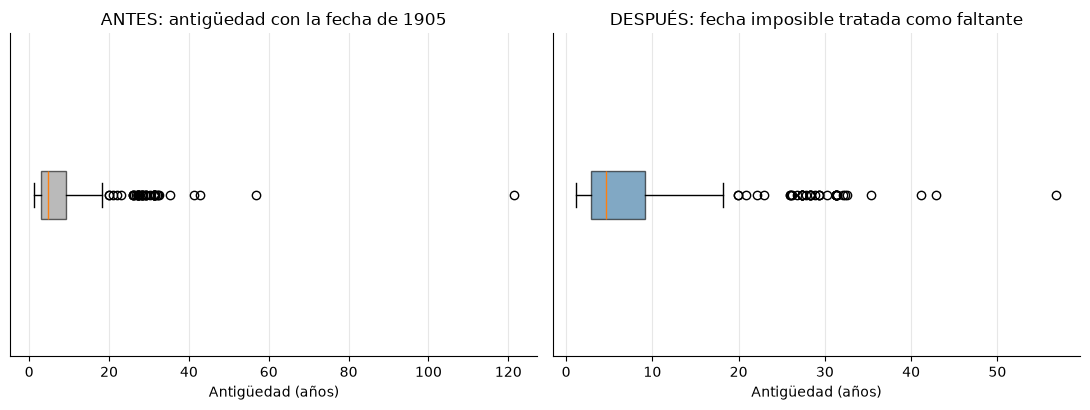

,ANTES (con la fecha de 1905),DESPUÉS (fecha imposible = faltante)
registros con dato,298.0,297.0
promedio (años),9.0,8.7
mediana (años),4.6,4.6
máximo (años),121.3,56.8


In [64]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))

ejes[0].boxplot(df["antiguedad_original"].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor=GRIS, alpha=0.6))
ejes[0].set_title("ANTES: antigüedad con la fecha de 1905")
ejes[0].set_xlabel("Antigüedad (años)"); ejes[0].set_yticks([])

ejes[1].boxplot(df["antiguedad_anios"].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor=AZUL, alpha=0.6))
ejes[1].set_title("DESPUÉS: fecha imposible tratada como faltante")
ejes[1].set_xlabel("Antigüedad (años)"); ejes[1].set_yticks([])

plt.tight_layout(); plt.show()

resumen_antiguedad = pd.DataFrame({
    "ANTES (con la fecha de 1905)": df["antiguedad_original"].agg(["count", "mean", "median", "max"]),
    "DESPUÉS (fecha imposible = faltante)": df["antiguedad_anios"].agg(["count", "mean", "median", "max"]),
}).round(1)
resumen_antiguedad.index = ["registros con dato", "promedio (años)", "mediana (años)", "máximo (años)"]
resumen_antiguedad

### 3.7 Registros duplicados

**1. Qué se hace:** buscar filas que parezcan la **misma inscripción repetida** y eliminarlas.

**2. Por qué:** un duplicado cuenta dos veces a la misma persona y sesga todos los porcentajes.

**Regla de decisión (importante):** que *dos filas tengan el mismo nombre de emprendimiento no basta* para llamarlas duplicadas. Por ejemplo, "El Rincón de las Manualidades" aparece dos veces, pero con **edades distintas** (76 y 64 años): son **dos personas** de un mismo negocio colectivo. Por eso solo se consideran duplicadas las filas que coinciden **a la vez** en nombre del emprendimiento, descripción, edad y género.

**3. Herramienta:** `pandas` (`.duplicated`).

In [65]:
columnas_clave = ["nombre", "descripcion", "edad", "genero_limpio"]

# Mostramos primero los casos de nombre repetido, para ver por qué no todos son duplicados reales
repetidos_nombre = df[df.duplicated("nombre", keep=False)].sort_values("nombre")
print("Filas con nombre de emprendimiento repetido:", len(repetidos_nombre))

es_duplicado = df.duplicated(subset=columnas_clave, keep="first")      # True = repetición exacta de otra fila
print("Duplicados reales (nombre + descripción + edad + género iguales):", es_duplicado.sum())
print(df.loc[es_duplicado, ["item", "nombre", "descripcion", "edad", "genero_limpio"]].to_string(index=False))

filas_antes = len(df)
df = df[~es_duplicado].reset_index(drop=True)                          # nos quedamos con la primera aparición
print(f"\nFilas antes: {filas_antes} | después de quitar duplicados: {len(df)}")

Filas con nombre de emprendimiento repetido: 12
Duplicados reales (nombre + descripción + edad + género iguales): 3
 item            nombre                                       descripcion  edad genero_limpio
  143 OBLEAS VILLARREAL                   Obleas y productos alimenticios    41      Femenino
  182  Caseritas Postre                                   Postres lácteos    28      Femenino
  206    Magnolia Cakes Elaboración de productos de resposteria artesanal    38      Femenino

Filas antes: 298 | después de quitar duplicados: 295


### 3.8 Creación de variables nuevas (ingeniería de variables)

**1. Qué se hace:** construir indicadores a partir de lo que **sí** existe en el archivo.

**2. Por qué:** el archivo no trae ingresos y pocas varaiables numericas medibles, por lo tanto estas nuevas variables permiten comparar grupos y medir qué tan formalizado y consolidado está cada negocio.

| Variable nueva | Cómo se calcula | Para qué sirve |
|---|---|---|
| `antiguedad_anios` | Fecha de corte − fecha de creación | Qué tan consolidado/antiguo es el negocio |
| `rango_antiguedad` | Agrupa la antigüedad: hasta 2, 2–5, 5–10, más de 10 años | Comparar negocios nuevos y antiguos |
| `grupo_edad` | Agrupa la edad: hasta 29, 30–39, 40–49, 50–59, 60 o más | Comparar generaciones |
| `indice_formalizacion` | **Suma de 3 puntos:** Cámara de Comercio (1) + RUT (1) + Página web (1) | Qué tan formal y visible es el negocio (0 = nada, 3 = todo) |
| `nivel_formalizacion` | Etiqueta del índice: Informal, Básico, Intermedio, Alto | Facilita leer gráficos |
| `tiene_empleados` y `tamano` | Empleados > 0; y 0 / 1–2 / 3 o más | Tamaño del negocio |
| `indice_madurez` (0–100) | **40 %** formalización + **30 %** antigüedad (con tope de 10 años) + **30 %** empleados (con tope de 5) | Un solo indicador resumen del grado de consolidación |

**Sobre el índice de madurez:** es un **indicador construido** con pesos que se define por criterio (se da más peso a la formalización porque es lo que la Alcaldía puede impulsar). **No es un ingreso ni una medida oficial**; sirve para **comparar grupos entre sí**. Los **topes** (10 años y 5 empleados) evitan que unos pocos casos extremos dominen el índice. Si falta la antigüedad (fecha imposible), se usa la mediana de antigüedad para no perder a esa persona.

In [66]:
# --- Indicadores de formalización: convertimos Sí/No en 1/0 y sumamos ---
df["tiene_camara"] = (df["camara_comercio_limpio"] == "Sí").astype(int)
df["tiene_rut"] = (df["rut_limpio"] == "Sí").astype(int)
df["tiene_web"] = (df["pagina_web_limpio"] == "Sí").astype(int)
df["indice_formalizacion"] = df["tiene_camara"] + df["tiene_rut"] + df["tiene_web"]      # de 0 a 3

etiquetas_formalizacion = {0: "Informal (0)", 1: "Básico (1)", 2: "Intermedio (2)", 3: "Alto (3)"}
df["nivel_formalizacion"] = pd.Categorical(
    df["indice_formalizacion"].map(etiquetas_formalizacion),
    categories=list(etiquetas_formalizacion.values()), ordered=True)

# --- Tamaño por empleados ---
df["tiene_empleados"] = (df["empleados"] > 0).astype(int)
df["tamano"] = pd.cut(df["empleados"], bins=[-1, 0, 2, 100],
                      labels=["Unipersonal (0)", "1 a 2 empleados", "3 o más empleados"])

# --- Grupos de edad y de antigüedad ---
df["grupo_edad"] = pd.cut(df["edad"], bins=[0, 29, 39, 49, 59, 120],
                          labels=["Hasta 29", "30-39", "40-49", "50-59", "60 o más"])
df["rango_antiguedad"] = pd.cut(df["antiguedad_anios"], bins=[-0.1, 2, 5, 10, 200],
                                labels=["Hasta 2 años", "2 a 5 años", "5 a 10 años", "Más de 10 años"])

# --- Índice de madurez (0 a 100) ---
antig_con_tope = df["antiguedad_anios"].fillna(df["antiguedad_anios"].median()).clip(upper=10)   # tope de 10 años
emp_con_tope = df["empleados"].clip(upper=5)                                                      # tope de 5 empleados
df["indice_madurez"] = (100 * (0.40 * df["indice_formalizacion"] / 3
                               + 0.30 * antig_con_tope / 10
                               + 0.30 * emp_con_tope / 5)).round(1)

# ANTES -> DESPUÉS: columnas disponibles y ejemplos de cómo se construyó cada variable nueva
print(f"Columnas en el archivo original: {df_original.shape[1]}  ->  columnas ahora (originales + limpias + nuevas): {df.shape[1]}")
print("\nEjemplos (columnas de la izquierda = datos ORIGINALES; columnas de la derecha = variables NUEVAS):")
df[["camara_comercio", "rut", "pagina_web", "indice_formalizacion", "nivel_formalizacion",
    "edad", "grupo_edad", "fecha_creacion", "antiguedad_anios", "rango_antiguedad",
    "empleados", "tamano", "indice_madurez"]].head(8)

Columnas en el archivo original: 19  ->  columnas ahora (originales + limpias + nuevas): 45

Ejemplos (columnas de la izquierda = datos ORIGINALES; columnas de la derecha = variables NUEVAS):


,camara_comercio,rut,pagina_web,indice_formalizacion,nivel_formalizacion,edad,grupo_edad,fecha_creacion,antiguedad_anios,rango_antiguedad,empleados,tamano,indice_madurez
0,NO,SI,NO,1,Básico (1),42,40-49,2023-05-18,3.5,2 a 5 años,0,Unipersonal (0),23.8
1,NO,SI,NO,1,Básico (1),51,50-59,2023-01-01,3.9,2 a 5 años,0,Unipersonal (0),25.0
2,NO,NO,NO,0,Informal (0),51,50-59,2014-01-01,12.9,Más de 10 años,0,Unipersonal (0),30.0
3,NO,SI,SI,2,Intermedio (2),51,50-59,2023-05-01,3.5,2 a 5 años,0,Unipersonal (0),37.2
4,SI,SI,NO,2,Intermedio (2),52,50-59,2020-01-01,6.9,5 a 10 años,2,1 a 2 empleados,59.4
5,SI,SI,NO,2,Intermedio (2),68,60 o más,2012-01-01,14.9,Más de 10 años,0,Unipersonal (0),56.7
6,SI,SI,NO,2,Intermedio (2),38,30-39,2023-09-11,3.2,2 a 5 años,0,Unipersonal (0),36.3
7,NO,SI,NO,1,Básico (1),62,60 o más,2023-01-01,3.9,2 a 5 años,0,Unipersonal (0),25.0


### 3.9 Comparación antes / después de la limpieza

**1. Qué se hace:** mostrar con una tabla y gráficos cuánto "se ordenó" el archivo.

**2. Por qué:** es la evidencia de que la limpieza **mejoró la calidad** de los datos: ahora una categoría real corresponde a una sola etiqueta.

                  Variable  Valores distintos ANTES  Categorías DESPUÉS  Reducción (%)
                    Género                        5                   2           60.0
         Tipo de documento                        8                   4           50.0
   Municipio de residencia                        9                   2           78.0
   Zona del emprendimiento                        4                   3           25.0
        Nivel de formación                       43                   8           81.0
           Línea económica                       80                   8           90.0
      Población vulnerable                       13                   6           54.0
¿Tiene Cámara de Comercio?                        6                   2           67.0


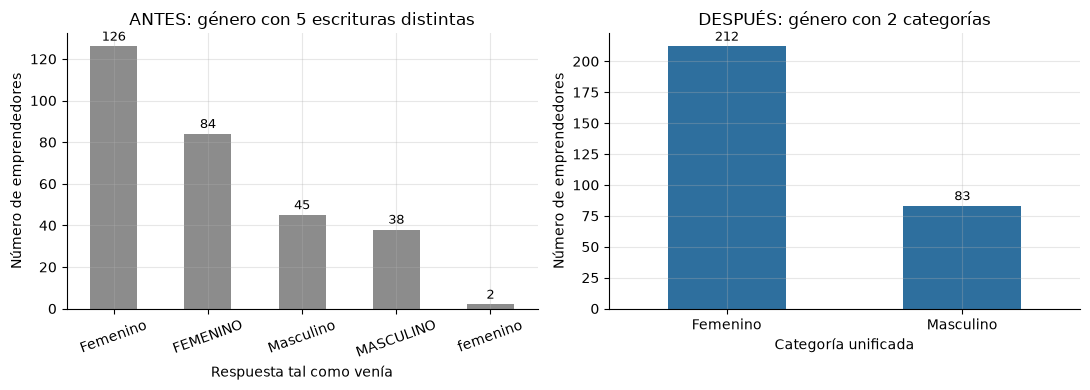

In [67]:
comparacion = pd.DataFrame({
    "Variable": ["Género", "Tipo de documento", "Municipio de residencia", "Zona del emprendimiento",
                 "Nivel de formación", "Línea económica", "Población vulnerable", "¿Tiene Cámara de Comercio?"],
    "Valores distintos ANTES": [df["genero"].nunique(), df["tipo_id"].nunique(), df["municipio_res"].nunique(),
                                df["zona_emp"].nunique(), df["formacion"].nunique(), df["linea_economica"].nunique(),
                                df["poblacion"].nunique(), df["camara_comercio"].nunique()],
    "Categorías DESPUÉS": [df["genero_limpio"].nunique(), df["tipo_id_limpio"].nunique(), df["municipio_limpio"].nunique(),
                           df["zona_emp_limpia"].nunique(), df["formacion_limpia"].nunique() + 1,   # +1 por 'Sin dato'
                           df["linea_grupo"].nunique(), df["poblacion_limpia"].nunique(), df["camara_comercio_limpio"].nunique()],
})
comparacion["Reducción (%)"] = ((1 - comparacion["Categorías DESPUÉS"] / comparacion["Valores distintos ANTES"]) * 100).round(0)
print(comparacion.to_string(index=False))

# Gráfico: género antes vs. después
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
df["genero"].value_counts().plot.bar(ax=ejes[0], color=GRIS, rot=20)
etiquetar(ejes[0]); ejes[0].set_title("ANTES: género con 5 escrituras distintas")
ejes[0].set_ylabel("Número de emprendedores"); ejes[0].set_xlabel("Respuesta tal como venía")

df["genero_limpio"].value_counts().plot.bar(ax=ejes[1], color=AZUL, rot=0)
etiquetar(ejes[1]); ejes[1].set_title("DESPUÉS: género con 2 categorías")
ejes[1].set_ylabel("Número de emprendedores"); ejes[1].set_xlabel("Categoría unificada")
plt.tight_layout(); plt.show()

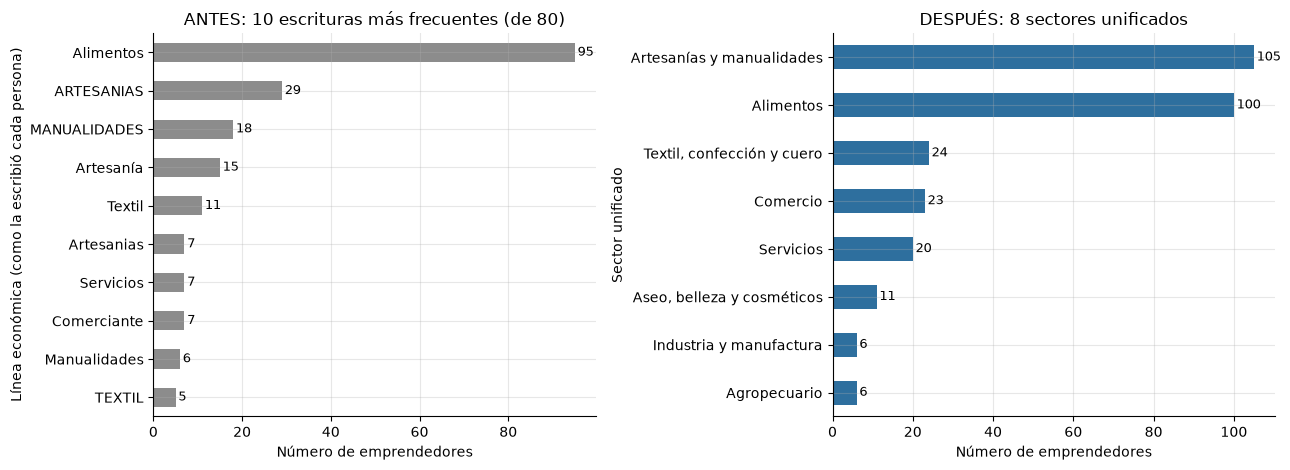

In [68]:
# Gráfico: línea económica antes (80 valores, solo los 10 más frecuentes) vs. después (sectores)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))

df["linea_economica"].value_counts().head(10).sort_values().plot.barh(ax=ejes[0], color=GRIS)
etiquetar(ejes[0]); ejes[0].set_title("ANTES: 10 escrituras más frecuentes (de 80)")
ejes[0].set_xlabel("Número de emprendedores"); ejes[0].set_ylabel("Línea económica (como la escribió cada persona)")

df["linea_grupo"].value_counts().sort_values().plot.barh(ax=ejes[1], color=AZUL)
etiquetar(ejes[1]); ejes[1].set_title(f"DESPUÉS: {df['linea_grupo'].nunique()} sectores unificados")
ejes[1].set_xlabel("Número de emprendedores"); ejes[1].set_ylabel("Sector unificado")
plt.tight_layout(); plt.show()

**5. Lectura del resultado.** La limpieza redujo entre **25 % y 89 %** el número de categorías según la variable (género: 5 → 2; formación: 43 → 7 niveles más "Sin dato"; línea económica: 80 → 8 sectores). En los gráficos "antes" las barras están partidas en variantes de lo mismo y es imposible comparar; en los gráficos "después" cada categoría es una sola barra y la lectura es inmediata.

### 3.10 Resumen del proceso de limpieza

| Problema encontrado | Decisión tomada | Justificación |
|---|---|---|
| Misma respuesta escrita de varias formas (mayúsculas, tildes, errores) | Normalizar y agrupar por palabras clave | Conteos confiables |
| Dato mal ubicado (apellido en "tipo de documento", municipio en "zona") | Marcar **"Sin dato"** | No se inventan valores |
| Respuestas vacías (3 en total: 1 zona y 2 líneas económicas) | Marcar "Sin dato" / usar la descripción para clasificar la línea | Conservar al resto de la información |
| Fecha imposible (1905) | Pasar a **faltante** | Evitar una antigüedad de 121 años que distorsiona |
| Dos negocios con fecha 2 años anterior al nacimiento del titular | **Conservar** y señalar | Plausible como negocio familiar heredado |
| Atípicos reales (muchos empleados, negocios muy antiguos) | **Conservar** y usar mediana + topes | Son datos legítimos |
| Filas repetidas | Eliminar solo si coinciden nombre + descripción + edad + género | Evitar contar dos veces a la misma persona sin eliminar personas distintas |
| Faltan ingresos | Crear indicadores verificables | No inventar datos |

### 3.11 Guardar la tabla limpia (cierre de la Parte 1)

**1. Qué se hace:** guardar la tabla ya limpia, con todas las variables nuevas, en el archivo `emprendedores_limpio.csv`.

**2. Por qué:** este archivo es el **puente entre las dos partes**. La Parte 2 (análisis) lo lee directamente y no vuelve a tocar el Excel original. Así la limpieza queda **separada y documentada**, y se puede repetir el análisis sin repetir la limpieza.

**3. Herramienta:** `pandas` (`.to_csv`). Se usa la codificación `utf-8-sig` para que las tildes se vean bien al abrir el archivo en Excel.

**4. ANTES → DESPUÉS del proceso completo:** se muestra cuántas filas y columnas tenía el archivo original y cuántas tiene la tabla limpia.

In [69]:
columnas_salida = ["item", "edad", "grupo_edad", "genero_limpio", "formacion_limpia", "municipio_limpio", "zona_res_limpia",
                   "zona_emp_limpia", "poblacion_limpia", "es_poblacion_vulnerable", "nombre", "fecha_limpia", "antiguedad_anios",
                   "rango_antiguedad", "modalidad_limpia", "descripcion", "linea_grupo", "tiene_camara", "tiene_rut", "tiene_web",
                   "indice_formalizacion", "nivel_formalizacion", "empleados", "tiene_empleados", "tamano", "indice_madurez"]
df[columnas_salida].to_csv("emprendedores_limpio.csv", index=False, encoding="utf-8-sig")

print(f"ANTES  (Excel original): {df_original.shape[0]} filas x {df_original.shape[1]} columnas")
print(f"DESPUÉS (tabla limpia) : {df[columnas_salida].shape[0]} filas x {len(columnas_salida)} columnas -> guardada en emprendedores_limpio.csv")

ANTES  (Excel original): 298 filas x 19 columnas
DESPUÉS (tabla limpia) : 295 filas x 26 columnas -> guardada en emprendedores_limpio.csv


**Fin de la Parte 1.** Los datos están limpios y listos. La Parte 2 empieza desde el archivo `emprendedores_limpio.csv`.

---
---
# PARTE 2 · Análisis estadístico, visualización y análisis de texto

> **Objetivo:** usar los datos **ya limpios** para responder preguntas, comparar grupos, analizar los textos y llegar a conclusiones para la toma de decisiones.
>
> **Punto de partida:** el archivo `emprendedores_limpio.csv` generado al final de la Parte 1. 

### Preparación del entorno (Parte 2)

**1. Qué se hace:** cargar las librerías de esta parte y definir el estilo de los gráficos.

**2. Por qué:** si se abre solo esta parte, esta celda deja todo listo. Cargar una librería dos veces no causa ningún problema.

**3. Herramientas nuevas en esta parte:**

| Librería | Para qué sirve |
|---|---|
| `matplotlib` | Dibujar los gráficos. |
| `scipy` | Pruebas estadísticas (¿la diferencia es real o casual?). |
| `nltk` (solo el *stemmer*) | Reducir las palabras a su raíz (*artesanías* → *artesan*). |
| `scikit-learn` | Convertir texto en números (Count y TF-IDF). |
| `wordcloud` | Dibujar la nube de palabras. |

In [70]:
import re, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from nltk.stem.snowball import SpanishStemmer                                   # raíz de las palabras (español)
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer    # texto -> números
from wordcloud import WordCloud                                                 # nube de palabras

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
AZUL, NARANJA, GRIS = "#2E6F9E", "#E07B39", "#8C8C8C"
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)

def etiquetar(ax):
    # Escribe el valor encima de cada barra
    for contenedor in ax.containers:
        ax.bar_label(contenedor, fontsize=9, padding=2)

### Carga de la tabla limpia

**1. Qué se hace :** leer `emprendedores_limpio.csv` y **restaurar el orden lógico** de las categorías (por ejemplo, formación: Primaria < Bachiller < Técnico < ... < Posgrado), porque un archivo CSV guarda todo como texto simple y se pierde esa información.

**2. Por qué:** sin el orden, los gráficos mostrarían las categorías en orden alfabético y no en el orden natural.

**3. Herramienta:** `pandas` (`pd.read_csv`, `pd.Categorical`).

**4. ANTES → DESPUÉS:** se compara la tabla limpia con el archivo original (cuántos registros y variables) para confirmar que se cargó lo correcto.

In [71]:
df = pd.read_csv("emprendedores_limpio.csv", encoding="utf-8-sig", parse_dates=["fecha_limpia"])

# Restaurar el orden de las categorías ordenadas
orden = {
    "formacion_limpia":    ["Sin estudios", "Primaria", "Bachiller o secundaria", "Técnico", "Tecnólogo", "Profesional", "Posgrado"],
    "nivel_formalizacion": ["Informal (0)", "Básico (1)", "Intermedio (2)", "Alto (3)"],
    "tamano":              ["Unipersonal (0)", "1 a 2 empleados", "3 o más empleados"],
    "grupo_edad":          ["Hasta 29", "30-39", "40-49", "50-59", "60 o más"],
    "rango_antiguedad":    ["Hasta 2 años", "2 a 5 años", "5 a 10 años", "Más de 10 años"],
}
for columna, categorias in orden.items():
    df[columna] = pd.Categorical(df[columna], categories=categorias, ordered=True)

print("ANTES  (Excel original)  : 298 filas x 19 columnas, con escrituras desordenadas")
print(f"DESPUÉS (tabla limpia)   : {df.shape[0]} filas x {df.shape[1]} columnas, con categorías unificadas y variables nuevas")
pd.set_option("display.max_columns", None); df.head(5)

ANTES  (Excel original)  : 298 filas x 19 columnas, con escrituras desordenadas
DESPUÉS (tabla limpia)   : 295 filas x 26 columnas, con categorías unificadas y variables nuevas


,item,edad,grupo_edad,genero_limpio,formacion_limpia,municipio_limpio,zona_res_limpia,zona_emp_limpia,poblacion_limpia,es_poblacion_vulnerable,nombre,fecha_limpia,antiguedad_anios,rango_antiguedad,modalidad_limpia,descripcion,linea_grupo,tiene_camara,tiene_rut,tiene_web,indice_formalizacion,nivel_formalizacion,empleados,tiene_empleados,tamano,indice_madurez
0,1,42,40-49,Femenino,Tecnólogo,Facatativá,Urbano,Urbano,Discapacidad,Sí,DELICIAS PA TÍ,2023-05-18,3.5,2 a 5 años,Individual,PRODUCCION Y COMERCIALIZACION DE PRODUCTOS LACTEOS,Alimentos,0,1,0,1,Básico (1),0,0,Unipersonal (0),23.8
1,2,51,50-59,Masculino,Bachiller o secundaria,Facatativá,Urbano,Urbano,Ninguna,No,ARTESANIAS STON AGE ART,2023-01-01,3.9,2 a 5 años,Individual,PRODUCCION Y COMERCIALIZACION DE MANILLAS,Artesanías y manualidades,0,1,0,1,Básico (1),0,0,Unipersonal (0),25.0
2,3,51,50-59,Femenino,Bachiller o secundaria,Facatativá,Urbano,Urbano,Ninguna,No,LAS DELICIAS DE LA MAZORCA,2014-01-01,12.9,Más de 10 años,Individual,"ELABORACIÓN Y VENTAS ENVUELTOS DE MAZORCA, AREPAS, TINTOS",Alimentos,0,0,0,0,Informal (0),0,0,Unipersonal (0),30.0
3,4,51,50-59,Femenino,Tecnólogo,Facatativá,Urbano,Urbano,Ninguna,No,InspirARTE,2023-05-01,3.5,2 a 5 años,Individual,Producción y comercialización de productos Crochet,Artesanías y manualidades,0,1,1,2,Intermedio (2),0,0,Unipersonal (0),37.2
4,5,52,50-59,Femenino,Tecnólogo,Facatativá,Rural,Rural,Ninguna,No,SHAROLANA,2020-01-01,6.9,5 a 10 años,Individual,"TEJIDOS EN CROCHET, FINIGRANA, PAPEL, FIQUE",Artesanías y manualidades,1,1,0,2,Intermedio (2),2,1,1 a 2 empleados,59.4


## 4. Análisis y visualización

Con los datos ya limpios, respondemos preguntas concretas. 

### 4.1 ¿Quiénes son los emprendedores? Perfil general

**1. Qué se hace:** cuatro gráficos de barras: género, grupos de edad, nivel de formación y zona donde se desarrolla el emprendimiento.

**2. Por qué:** es el retrato básico de la población inscrita; sirve para saber a quién llegan los programas actuales.

**3. Herramienta:** `matplotlib` (vía `pandas`).

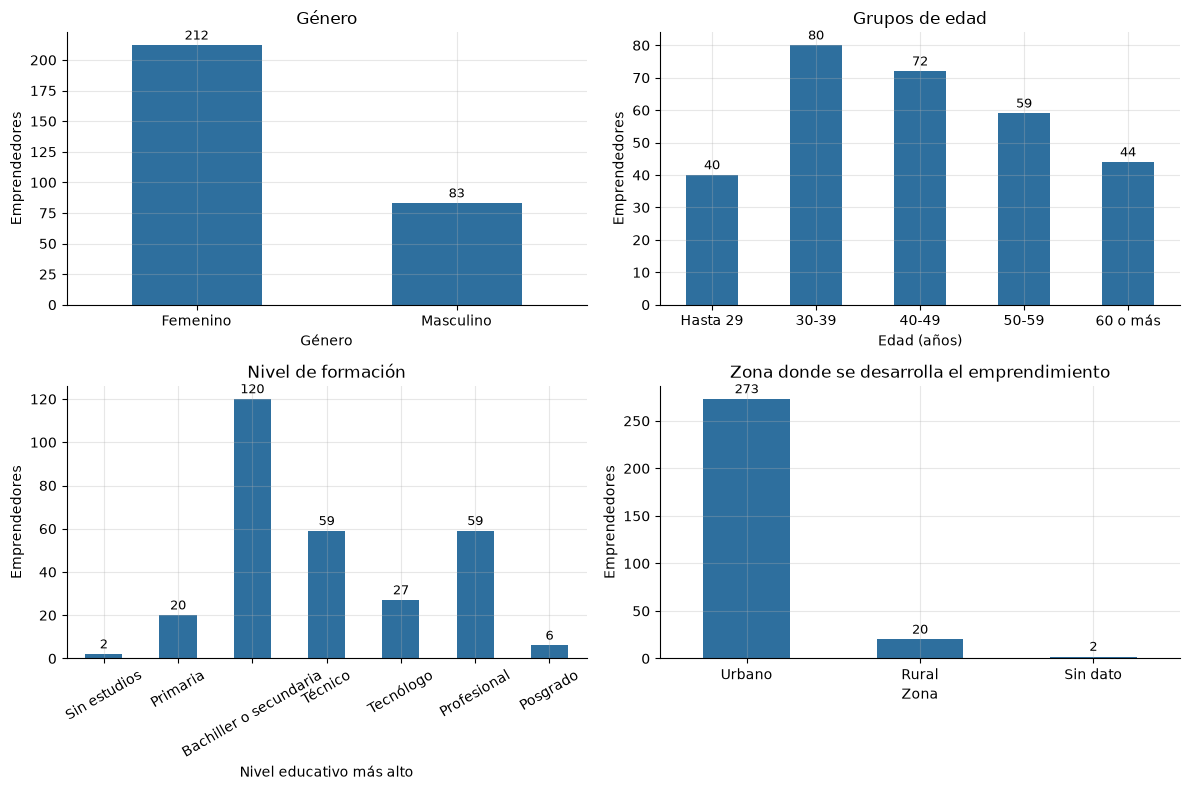

• Mujeres: 72% | Hombres: 28%
• Edad mediana: 43 años; 59% tiene 40 años o más
• Con formación técnica, tecnológica o profesional (o mayor): 51%
• Viven en zona rural: 6%
• Pertenecen a alguna población vulnerable o diferencial: 17%


In [72]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))

df["genero_limpio"].value_counts().plot.bar(ax=ejes[0, 0], color=AZUL, rot=0)
ejes[0, 0].set_title("Género"); ejes[0, 0].set_xlabel("Género"); ejes[0, 0].set_ylabel("Emprendedores")

df["grupo_edad"].value_counts().sort_index().plot.bar(ax=ejes[0, 1], color=AZUL, rot=0)
ejes[0, 1].set_title("Grupos de edad"); ejes[0, 1].set_xlabel("Edad (años)"); ejes[0, 1].set_ylabel("Emprendedores")

df["formacion_limpia"].value_counts().sort_index().plot.bar(ax=ejes[1, 0], color=AZUL, rot=30)
ejes[1, 0].set_title("Nivel de formación"); ejes[1, 0].set_xlabel("Nivel educativo más alto"); ejes[1, 0].set_ylabel("Emprendedores")

df["zona_emp_limpia"].value_counts().plot.bar(ax=ejes[1, 1], color=AZUL, rot=0)
ejes[1, 1].set_title("Zona donde se desarrolla el emprendimiento"); ejes[1, 1].set_xlabel("Zona"); ejes[1, 1].set_ylabel("Emprendedores")

for ax in ejes.flat:
    etiquetar(ax)
plt.tight_layout(); plt.show()

# Cifras clave en lenguaje natural (calculadas, no escritas a mano)
n = len(df)
print(f"• Mujeres: {(df['genero_limpio'] == 'Femenino').mean():.0%} | Hombres: {(df['genero_limpio'] == 'Masculino').mean():.0%}")
print(f"• Edad mediana: {df['edad'].median():.0f} años; {(df['edad'] >= 40).mean():.0%} tiene 40 años o más")
print(f"• Con formación técnica, tecnológica o profesional (o mayor): {(df['formacion_limpia'] >= 'Técnico').mean():.0%}")
print(f"• Viven en zona rural: {(df['zona_res_limpia'] == 'Rural').mean():.0%}")
print(f"• Pertenecen a alguna población vulnerable o diferencial: {(df['es_poblacion_vulnerable'] == 'Sí').mean():.0%}")

**Lectura del resultado.**

* **Predominan las mujeres:** casi **3 de cada 4** emprendedores inscritos (72 %).
* **Edad media-adulta:** el grupo más grande es el de **30 a 39 años**, y el 59 % tiene 40 años o más.
* **Formación:** la mayoría tiene como nivel más alto el **bachillerato** (cerca del 41 %), pero **1 de cada 2** (51 %) cuenta con formación técnica, tecnológica, profesional o de posgrado: no es una población sin estudios.
* **Territorio:** el emprendimiento es sobre todo **urbano** (94 %); la zona rural es pequeña (6 %).
* **Inclusión:** el **17 %** pertenece a alguna población vulnerable o diferencial (principalmente víctimas del conflicto armado y personas con discapacidad).

### 4.2 ¿En qué sectores emprenden?

**1. Qué se hace:** un gráfico de barras horizontales con el **porcentaje** de emprendedores por sector.

**2. Por qué:** muestra dónde se concentra el emprendimiento local y qué sectores son pequeños.

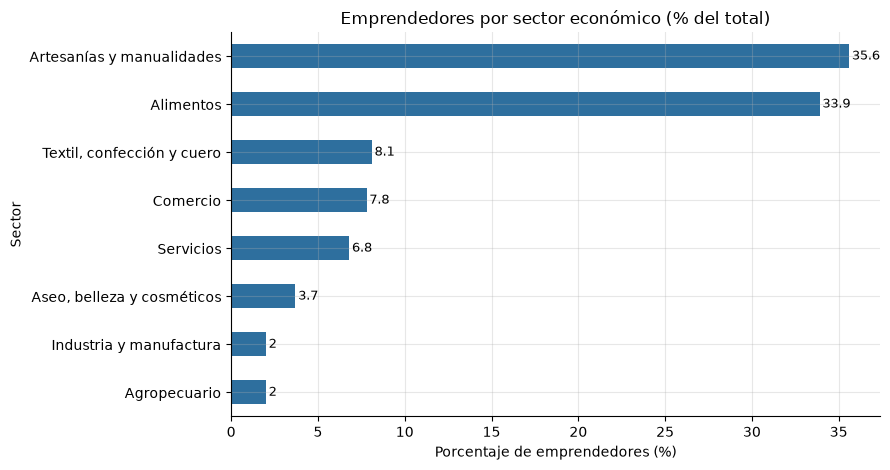

linea_grupo
Artesanías y manualidades     35.6
Alimentos                     33.9
Textil, confección y cuero     8.1
Comercio                       7.8
Servicios                      6.8
Aseo, belleza y cosméticos     3.7
Agropecuario                   2.0
Industria y manufactura        2.0


In [73]:
sector = df["linea_grupo"].value_counts()
porcentaje = (sector / len(df) * 100).round(1)

ax = porcentaje.sort_values().plot.barh(figsize=(9, 4.8), color=AZUL)
etiquetar(ax)
ax.set_title("Emprendedores por sector económico (% del total)")
ax.set_xlabel("Porcentaje de emprendedores (%)"); ax.set_ylabel("Sector")
plt.tight_layout(); plt.show()
print(porcentaje.to_string())

**Lectura del resultado.** **Siete de cada diez emprendedores se concentran en solo dos sectores:** *Artesanías y manualidades* (35,6 %) y *Alimentos* (33,9 %). Les siguen *Textil, confección y cuero* (8,1 %), *Comercio* (7,8 %) y *Servicios* (6,8 %). Sectores como agropecuario o industria son muy pequeños (2 % cada uno), por lo que no permiten conclusiones firmes.

### 4.3 ¿Cuándo se crearon los emprendimientos?

**1. Qué se hace:** contar cuántos emprendimientos se crearon cada año desde 2015.

**2. Por qué:** permite ver si el emprendimiento está creciendo o si hubo un "boom" reciente. *Ojo con una limitación:* el archivo solo incluye a quienes **se inscribieron**, no a todos los negocios creados cada año.

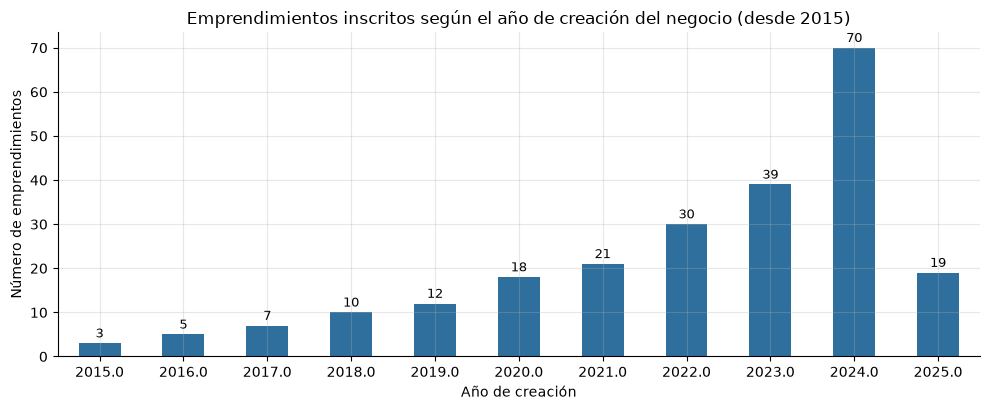

Emprendimientos por año de creación: {2015.0: 3, 2016.0: 5, 2017.0: 7, 2018.0: 10, 2019.0: 12, 2020.0: 18, 2021.0: 21, 2022.0: 30, 2023.0: 39, 2024.0: 70, 2025.0: 19}
• Creados desde 2022: 54% del total
• Con más de 10 años de antigüedad: 23%
• Antigüedad mediana: 4.6 años


In [74]:
por_anio = df["fecha_limpia"].dt.year.value_counts().sort_index()
por_anio = por_anio[por_anio.index >= 2015]

ax = por_anio.plot.bar(figsize=(10, 4.2), color=AZUL, rot=0)
etiquetar(ax)
ax.set_title("Emprendimientos inscritos según el año de creación del negocio (desde 2015)")
ax.set_xlabel("Año de creación"); ax.set_ylabel("Número de emprendimientos")
plt.tight_layout(); plt.show()

print("Emprendimientos por año de creación:", por_anio.to_dict())
print(f"• Creados desde 2022: {(df['fecha_limpia'].dt.year >= 2022).mean():.0%} del total")
print(f"• Con más de 10 años de antigüedad: {(df['antiguedad_anios'] > 10).mean():.0%}")
print(f"• Antigüedad mediana: {df['antiguedad_anios'].median():.1f} años")

**Lectura del resultado.** El emprendimiento inscrito es **joven y creciente**: el **54 %** de los negocios se creó **desde 2022** y la antigüedad mediana es de apenas **4,6 años**. El máximo está en 2024 (70 emprendimientos). Aun así, 1 de cada 4 (23 %) tiene más de 10 años, es decir, hay un núcleo de negocios consolidados.

*Nota:* 2025 aparece bajo porque el año está incompleto (el último negocio creado es de septiembre de 2025) y el pico de 2024 puede reflejar también **campañas de inscripción** y no solo más negocios nuevos.

### 4.4 ¿Qué tan formalizados están?

**1. Qué se hace:** dos gráficos: (a) el porcentaje de emprendimientos que tiene **Cámara de Comercio, RUT y página web**; (b) cuántos se ubican en cada **nivel de formalización** (0 a 3 puntos).

**2. Por qué:** la formalización es la palanca principal de política pública: abre acceso a crédito, contratación y programas de apoyo.

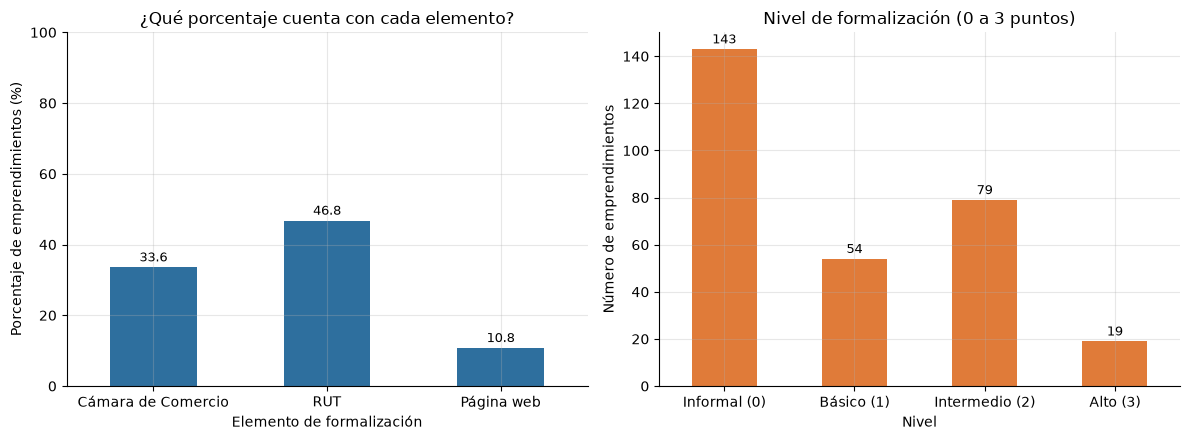

• Sin ninguno de los tres elementos (nivel Informal): 48%
• Con los tres elementos (nivel Alto): 6%


In [75]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) Porcentaje que SÍ tiene cada elemento
pct_formal = pd.Series({
    "Cámara de Comercio": df["tiene_camara"].mean() * 100,
    "RUT": df["tiene_rut"].mean() * 100,
    "Página web": df["tiene_web"].mean() * 100,
}).round(1)
pct_formal.plot.bar(ax=ejes[0], color=[AZUL, AZUL, AZUL], rot=0)
etiquetar(ejes[0])
ejes[0].set_title("¿Qué porcentaje cuenta con cada elemento?")
ejes[0].set_ylabel("Porcentaje de emprendimientos (%)"); ejes[0].set_xlabel("Elemento de formalización"); ejes[0].set_ylim(0, 100)

# (b) Distribución del nivel de formalización
df["nivel_formalizacion"].value_counts().sort_index().plot.bar(ax=ejes[1], color=NARANJA, rot=0)
etiquetar(ejes[1])
ejes[1].set_title("Nivel de formalización (0 a 3 puntos)")
ejes[1].set_ylabel("Número de emprendimientos"); ejes[1].set_xlabel("Nivel")

plt.tight_layout(); plt.show()
print(f"• Sin ninguno de los tres elementos (nivel Informal): {(df['indice_formalizacion'] == 0).mean():.0%}")
print(f"• Con los tres elementos (nivel Alto): {(df['indice_formalizacion'] == 3).mean():.0%}")

**Lectura del resultado.** La **formalización es baja**:

* Solo **1 de cada 3** (34 %) está registrado en Cámara de Comercio, **menos de la mitad** (47 %) tiene RUT y apenas **1 de cada 10** (11 %) tiene página web.
* **El 48 % no tiene ninguno de los tres elementos** (nivel "Informal") y solo el **6 %** los tiene todos.
* Dato útil: hay **44 emprendimientos con RUT pero sin Cámara de Comercio**; son los "más cercanos" a formalizarse del todo.

### 4.5 ¿Qué sectores están más formalizados? (comparación entre grupos)

**1. Qué se hace:** una **tabla resumen por sector** y un gráfico del índice de formalización promedio, **solo para sectores con 10 o más casos** (con menos casos, un promedio no es confiable).

**2. Por qué:** indica **dónde enfocar** la formalización: los sectores con índice bajo son los que más se beneficiarían.

,emprendedores,formalizacion_promedio,pct_con_camara,pct_con_empleados,madurez_mediana
linea_grupo,,,,,
Servicios,20,1.3,45.0,30.0,36.4
"Aseo, belleza y cosméticos",11,1.1,36.0,18.0,30.0
Agropecuario,6,1.0,33.0,17.0,27.3
Artesanías y manualidades,105,0.9,32.0,15.0,28.9
Alimentos,100,0.9,36.0,26.0,30.0
"Textil, confección y cuero",24,0.8,33.0,21.0,30.0
Comercio,23,0.7,22.0,17.0,30.0
Industria y manufactura,6,0.5,17.0,17.0,30.0


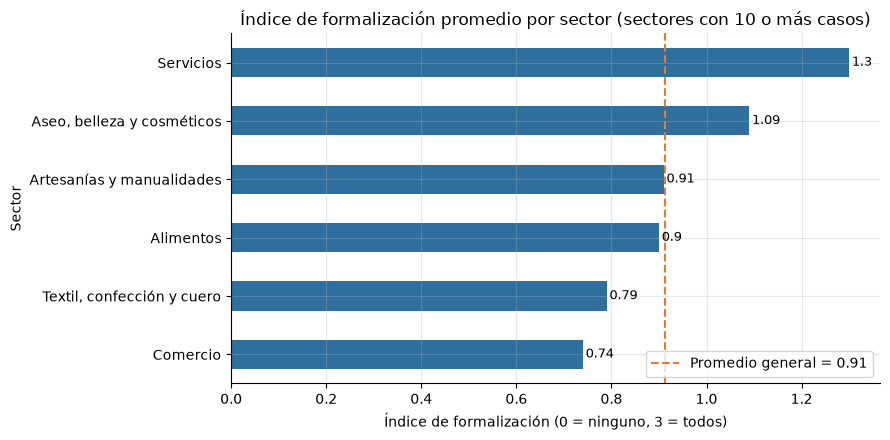

In [76]:
por_sector = df.groupby("linea_grupo").agg(
    emprendedores=("item", "count"),
    formalizacion_promedio=("indice_formalizacion", "mean"),
    pct_con_camara=("tiene_camara", "mean"),
    pct_con_empleados=("tiene_empleados", "mean"),
    madurez_mediana=("indice_madurez", "median"),
).round(2)
por_sector[["pct_con_camara", "pct_con_empleados"]] *= 100          # pasar proporciones a porcentajes
por_sector = por_sector.sort_values("formalizacion_promedio", ascending=False)
display(por_sector.round(1))

grandes = por_sector[por_sector["emprendedores"] >= 10].sort_values("formalizacion_promedio")
ax = grandes["formalizacion_promedio"].plot.barh(figsize=(9, 4.5), color=AZUL)
etiquetar(ax)
linea_prom = ax.axvline(df["indice_formalizacion"].mean(), color=NARANJA, linestyle="--", label=f"Promedio general = {df['indice_formalizacion'].mean():.2f}")
ax.set_title("Índice de formalización promedio por sector (sectores con 10 o más casos)")
ax.set_xlabel("Índice de formalización (0 = ninguno, 3 = todos)"); ax.set_ylabel("Sector")
ax.legend(handles=[linea_prom], loc="lower right")
plt.tight_layout(); plt.show()

**Lectura del resultado.** Entre los sectores con 10 o más casos, **Servicios** es el más formalizado (1,3 de 3 puntos; 45 % con Cámara de Comercio) y **Comercio** el menos (0,7; solo 22 % con Cámara), algo llamativo porque se esperaría que quien vende esté más formalizado. Los dos sectores más grandes (*Artesanías* y *Alimentos*) están en un punto intermedio (≈ 0,9, cerca del promedio general). *Alimentos* destaca por **generar más empleo** (26 % tiene empleados frente a 15 % en artesanías).

*Nota:* los sectores de 6 casos (agropecuario, industria) se muestran en la tabla pero **no se grafican** porque un promedio con tan pocos datos no es confiable.

### 4.6 ¿La formalización se relaciona con generar empleo?

**1. Qué se hace:** comparar el **porcentaje de emprendimientos que tienen empleados** según su nivel de formalización y según su modalidad (individual o colectiva).

**2. Por qué:** si los negocios más formalizados emplean más, formalizar tiene un beneficio social adicional (empleo local), lo que fortalece el argumento de política.

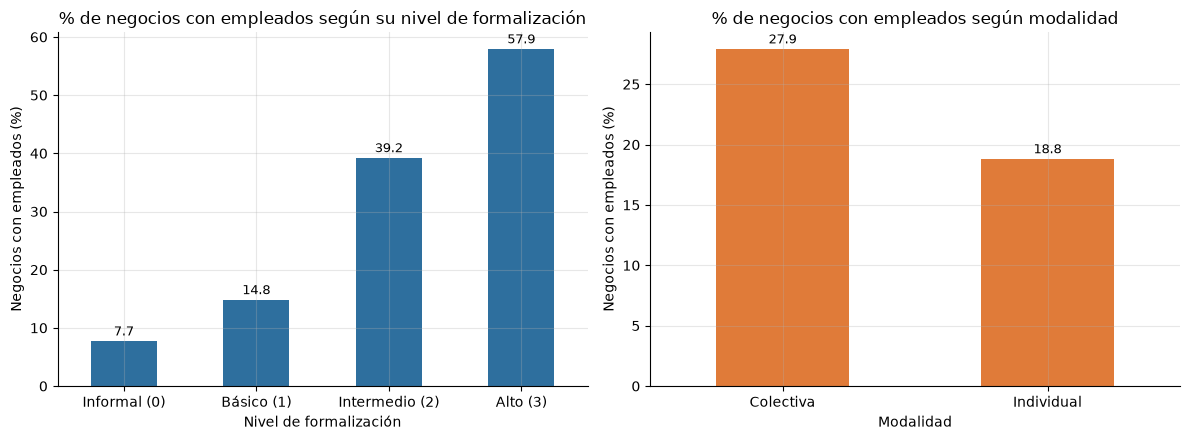

% con empleados por nivel de formalización: {'Informal (0)': 7.7, 'Básico (1)': 14.8, 'Intermedio (2)': 39.2, 'Alto (3)': 57.9}
% con empleados por modalidad: {'Colectiva': 27.9, 'Individual': 18.8}
Casos por nivel de formalización: {'Informal (0)': 143, 'Básico (1)': 54, 'Intermedio (2)': 79, 'Alto (3)': 19}


In [77]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

emp_por_nivel = (df.groupby("nivel_formalizacion", observed=True)["tiene_empleados"].mean() * 100).round(1)
emp_por_nivel.plot.bar(ax=ejes[0], color=AZUL, rot=0)
etiquetar(ejes[0])
ejes[0].set_title("% de negocios con empleados según su nivel de formalización")
ejes[0].set_xlabel("Nivel de formalización"); ejes[0].set_ylabel("Negocios con empleados (%)")

emp_por_modalidad = (df.groupby("modalidad_limpia")["tiene_empleados"].mean() * 100).round(1)
emp_por_modalidad.plot.bar(ax=ejes[1], color=NARANJA, rot=0)
etiquetar(ejes[1])
ejes[1].set_title("% de negocios con empleados según modalidad")
ejes[1].set_xlabel("Modalidad"); ejes[1].set_ylabel("Negocios con empleados (%)")

plt.tight_layout(); plt.show()
print("% con empleados por nivel de formalización:", emp_por_nivel.to_dict())
print("% con empleados por modalidad:", emp_por_modalidad.to_dict())
print("Casos por nivel de formalización:", df["nivel_formalizacion"].value_counts().sort_index().to_dict())

**Lectura del resultado.** La relación es **muy marcada**: entre los negocios **informales solo el 8 %** tiene empleados; con formalización intermedia sube a **39 %** y con formalización alta a **58 %**. Por modalidad, los negocios **colectivos** emplean más (28 %) que los **individuales** (19 %).

*Nota:* esto muestra **asociación, no causalidad**. Puede ser que formalizarse permita crecer y contratar, o que los negocios más grandes se formalicen porque lo necesitan; los datos no permiten saber cuál es la dirección.

### 4.7 Índice de madurez: ¿qué grupos están más consolidados?

**1. Qué se hace:** comparar el índice de madurez (0–100) entre sectores (diagrama de caja) y entre niveles de formación (barras con la **mediana**).

**2. Por qué:** resume en un solo número qué tan consolidado está cada negocio y permite comparar grupos. Se usa la **mediana** (valor central) en lugar del promedio porque es menos sensible a unos pocos casos muy altos.

**Un diagrama de caja:** la línea central es la mediana; la caja contiene el 50 % central de los negocios; las "patas" muestran el rango habitual; los puntos son casos fuera de lo común.

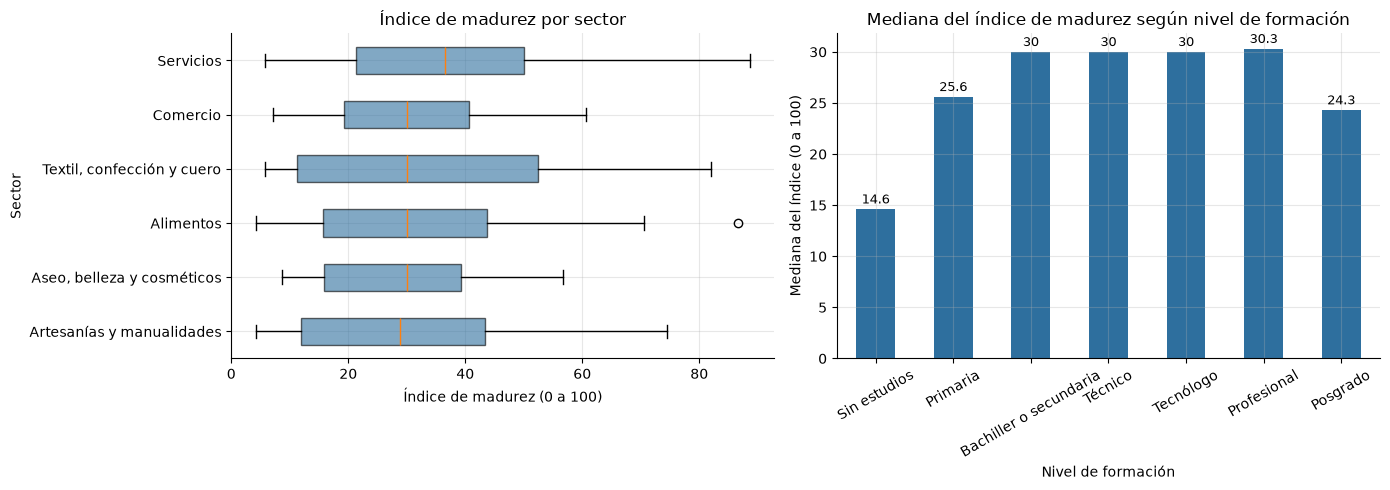

Mediana del índice de madurez por formación: {'Sin estudios': 14.6, 'Primaria': 25.6, 'Bachiller o secundaria': 30.0, 'Técnico': 30.0, 'Tecnólogo': 30.0, 'Profesional': 30.3, 'Posgrado': 24.3}
Mediana general del índice de madurez: 30.0


In [78]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Diagrama de caja por sector (solo sectores con 10+ casos)
sectores_ok = por_sector[por_sector["emprendedores"] >= 10].sort_values("madurez_mediana").index
datos_cajas = [df.loc[df["linea_grupo"] == s, "indice_madurez"] for s in sectores_ok]
ejes[0].boxplot(datos_cajas, vert=False, patch_artist=True, boxprops=dict(facecolor=AZUL, alpha=0.6))
ejes[0].set_yticklabels(sectores_ok)            # nombres de los sectores (se ponen aparte para funcionar en cualquier versión de matplotlib)
ejes[0].set_title("Índice de madurez por sector")
ejes[0].set_xlabel("Índice de madurez (0 a 100)"); ejes[0].set_ylabel("Sector")

# (b) Mediana por nivel de formación
madurez_formacion = df.groupby("formacion_limpia", observed=True)["indice_madurez"].median().round(1)
madurez_formacion.plot.bar(ax=ejes[1], color=AZUL, rot=30)
etiquetar(ejes[1])
ejes[1].set_title("Mediana del índice de madurez según nivel de formación")
ejes[1].set_xlabel("Nivel de formación"); ejes[1].set_ylabel("Mediana del índice (0 a 100)")

plt.tight_layout(); plt.show()
print("Mediana del índice de madurez por formación:", madurez_formacion.to_dict())
print("Mediana general del índice de madurez:", df["indice_madurez"].median())

**Lectura del resultado.**

* **Por sector:** *Servicios* tiene la mediana más alta (36,4 puntos); el resto de sectores se ubica entre 27 y 30 puntos, sin diferencias grandes.
* **Por formación:** desde *Bachiller* hasta *Profesional* la mediana es prácticamente la misma (≈ 30 puntos). **Tener más estudios no se traduce, por sí solo, en un negocio más maduro** en este grupo. Las barras de *Sin estudios* (2 casos) y *Posgrado* (6 casos) se basan en muy pocos datos y no deben interpretarse.
* La mediana general del índice es 30 sobre 100: la mayoría de los emprendimientos está en una etapa **inicial de consolidación**.

### 4.8 Relaciones entre variables numéricas (correlación)

**1. Qué se hace:** calcular la **correlación de Spearman** entre edad, antigüedad, empleados e índice de formalización y mostrarla como un **mapa de calor**.

**2. Por qué:** la correlación indica si dos variables "suben juntas" (valores cercanos a +1), "una sube y la otra baja" (cercanos a −1) o no se relacionan (cercanos a 0). Se usa **Spearman** (basada en rangos) porque funciona bien con datos que no son simétricos, como los empleados (muchos ceros).

**Nota:** *correlación no es causalidad*, que dos variables se muevan juntas no prueba que una cause la otra. No se incluye el índice de madurez porque está construido con estas mismas variables y la relación sería artificial.

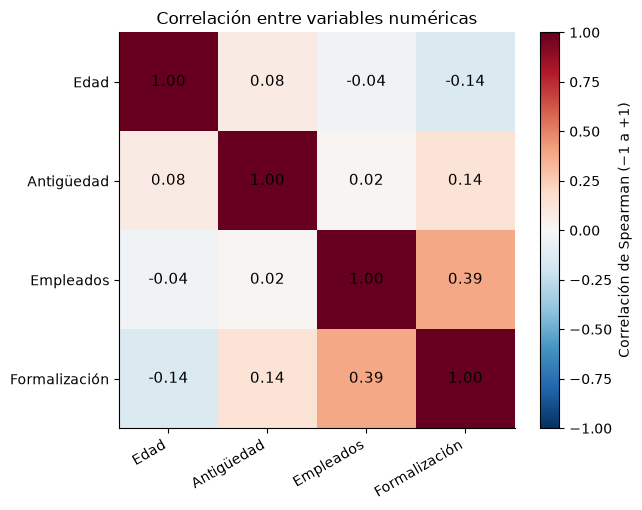

,edad,antiguedad_anios,empleados,indice_formalizacion
edad,1.00,0.08,-0.04,-0.14
antiguedad_anios,0.08,1.00,0.02,0.14
empleados,-0.04,0.02,1.00,0.39
indice_formalizacion,-0.14,0.14,0.39,1.00


In [79]:
variables_corr = ["edad", "antiguedad_anios", "empleados", "indice_formalizacion"]
nombres_corr = ["Edad", "Antigüedad", "Empleados", "Formalización"]
corr = df[variables_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)      # rojo = relación positiva, azul = negativa
ax.grid(False)
ax.set_xticks(range(4)); ax.set_xticklabels(nombres_corr, rotation=30, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(nombres_corr)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=11)
fig.colorbar(im, label="Correlación de Spearman (−1 a +1)")
ax.set_title("Correlación entre variables numéricas")
plt.tight_layout(); plt.show()
corr.round(2)

**Lectura del resultado.**

* La relación más fuerte es **formalización ↔ empleados (0,39)**, de intensidad **moderada**: los negocios más formalizados tienden a tener empleados.
* **Antigüedad ↔ formalización (0,14)** y **edad ↔ formalización (−0,14)** son relaciones **débiles**: los negocios más antiguos son algo más formales y las personas de más edad algo menos.
* El resto está **cerca de cero**: por ejemplo, la edad casi no se relaciona con el número de empleados.

### 4.9 Pruebas estadísticas: ¿la diferencia es real o casual?

**1. Qué se hace:** aplicar tres pruebas sencillas para ver si algunas diferencias observadas pueden deberse solo al azar de la muestra.

**2. Por qué:** ver que un grupo tiene un promedio distinto a otro no basta; con pocos casos, la diferencia podría ser casualidad. La prueba entrega un **valor p**:

* **p < 0,05** → la diferencia **probablemente no es casualidad** (se llama "estadísticamente significativa").
* **p ≥ 0,05** → **no hay evidencia suficiente** de una diferencia real (no significa que sean iguales).

**Las tres pruebas:**
1. **Mann-Whitney:** ¿el índice de madurez es distinto entre mujeres y hombres?
2. **Chi-cuadrado:** ¿tener Cámara de Comercio y tener empleados están asociados?
3. **Spearman:** ¿los negocios más antiguos están más formalizados?

**3. Herramienta:** `scipy.stats`.

In [80]:
def interpretar(p):
    return "diferencia/relación estadísticamente significativa (p < 0,05)" if p < 0.05 else "sin evidencia suficiente de diferencia (p ≥ 0,05)"

# 1) Madurez: mujeres vs. hombres (Mann-Whitney: compara dos grupos sin exigir distribución normal)
mujeres = df.loc[df["genero_limpio"] == "Femenino", "indice_madurez"]
hombres = df.loc[df["genero_limpio"] == "Masculino", "indice_madurez"]
u, p1 = stats.mannwhitneyu(mujeres, hombres)
print(f"1) Madurez mujeres (mediana {mujeres.median():.1f}) vs. hombres (mediana {hombres.median():.1f}): p = {p1:.3f} -> {interpretar(p1)}")

# 2) Cámara de Comercio y empleados (Chi-cuadrado sobre tabla de contingencia)
tabla = pd.crosstab(df["tiene_camara"], df["tiene_empleados"])
chi2, p2, _, _ = stats.chi2_contingency(tabla)
print(f"2) Cámara de Comercio vs. tener empleados: p = {p2:.4f} -> {interpretar(p2)}")
print("   Tabla (filas: Cámara 0=No/1=Sí; columnas: empleados 0=No/1=Sí):")
print(tabla.to_string())

# 3) Antigüedad y formalización (Spearman)
datos = df[["antiguedad_anios", "indice_formalizacion"]].dropna()
rho, p3 = stats.spearmanr(datos["antiguedad_anios"], datos["indice_formalizacion"])
print(f"3) Antigüedad vs. formalización: rho = {rho:.2f}, p = {p3:.4f} -> {interpretar(p3)}")

1) Madurez mujeres (mediana 27.7) vs. hombres (mediana 30.0): p = 0.009 -> diferencia/relación estadísticamente significativa (p < 0,05)
2) Cámara de Comercio vs. tener empleados: p = 0.0000 -> diferencia/relación estadísticamente significativa (p < 0,05)
   Tabla (filas: Cámara 0=No/1=Sí; columnas: empleados 0=No/1=Sí):
tiene_empleados    0   1
tiene_camara            
0                179  17
1                 55  44
3) Antigüedad vs. formalización: rho = 0.14, p = 0.0173 -> diferencia/relación estadísticamente significativa (p < 0,05)


**Lectura del resultado.**

1. **Mujeres vs. hombres (p = 0,009):** la diferencia **sí es estadísticamente significativa**. Las mujeres tienen una madurez mediana de 27,7 frente a 30,0 de los hombres. En detalle: formalización promedio de 0,85 vs. 1,06 y empleadoras 17 % vs. 29 %. Es una **brecha real en este grupo**, aunque los datos no explican *por qué* se da.
2. **Cámara de Comercio y empleo (p < 0,001):** relación muy fuerte. De los 99 negocios con Cámara de Comercio, **44 (44 %) tienen empleados**; de los 196 sin Cámara, solo **17 (9 %)**.
3. **Antigüedad y formalización (rho = 0,14, p = 0,017):** existe, pero es **débil**: ser significativa no significa que sea grande. Que un negocio sea más antiguo **no garantiza** que esté más formalizado.

### 4.10 Poblaciones vulnerables o diferenciales

**1. Qué se hace:** ver qué poblaciones están presentes y comparar el nivel de formalización entre quienes pertenecen a alguna y quienes no.

**2. Por qué:** si hay una brecha, los programas de formalización deberían tener un enfoque diferencial.

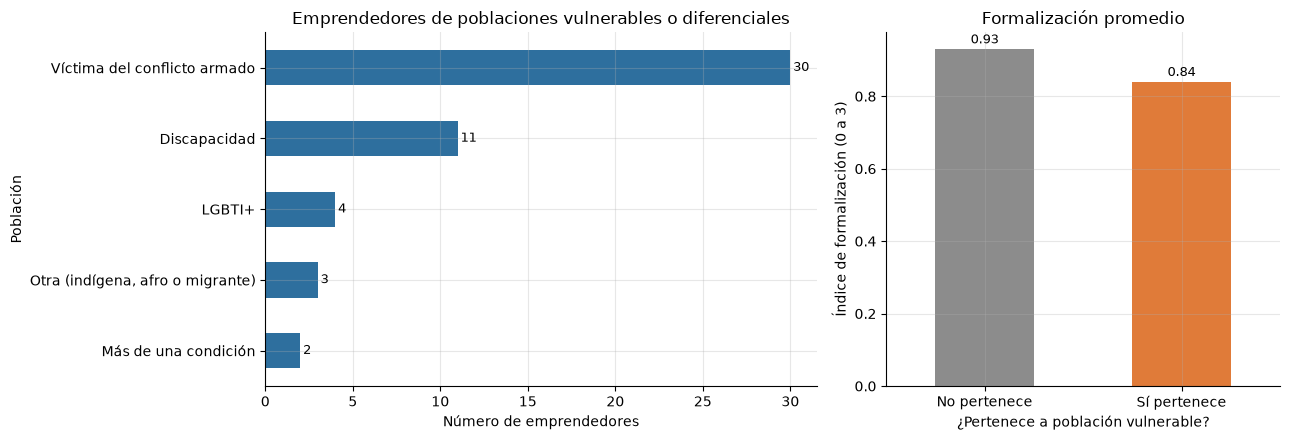

Formalización promedio: {'No pertenece': 0.93, 'Sí pertenece': 0.84}
% con empleados: {'No': 21.2, 'Sí': 18.0}
Prueba Mann-Whitney de formalización (vulnerable vs. no): p = 0.526


In [81]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})

df.loc[df["poblacion_limpia"] != "Ninguna", "poblacion_limpia"].value_counts().sort_values().plot.barh(ax=ejes[0], color=AZUL)
etiquetar(ejes[0])
ejes[0].set_title("Emprendedores de poblaciones vulnerables o diferenciales")
ejes[0].set_xlabel("Número de emprendedores"); ejes[0].set_ylabel("Población")

form_pob = df.groupby("es_poblacion_vulnerable")["indice_formalizacion"].mean().round(2)
form_pob.index = ["No pertenece", "Sí pertenece"]
form_pob.plot.bar(ax=ejes[1], color=[GRIS, NARANJA], rot=0)
etiquetar(ejes[1])
ejes[1].set_title("Formalización promedio")
ejes[1].set_xlabel("¿Pertenece a población vulnerable?"); ejes[1].set_ylabel("Índice de formalización (0 a 3)")

plt.tight_layout(); plt.show()
print("Formalización promedio:", form_pob.to_dict())
print("% con empleados:", (df.groupby("es_poblacion_vulnerable")["tiene_empleados"].mean() * 100).round(1).to_dict())
print("Prueba Mann-Whitney de formalización (vulnerable vs. no): p =", round(stats.mannwhitneyu(df.loc[df["es_poblacion_vulnerable"] == "Sí", "indice_formalizacion"], df.loc[df["es_poblacion_vulnerable"] == "No", "indice_formalizacion"])[1], 3))

**5. Lectura del resultado.** Las poblaciones más representadas son las **víctimas del conflicto armado** (30 personas) y las **personas con discapacidad** (11). La formalización promedio de quienes pertenecen a alguna de estas poblaciones (0,84) es **muy parecida** a la de quienes no (0,93) y la prueba estadística (p = 0,53) **no encuentra diferencia significativa**. Es decir, **no hay evidencia de una brecha de formalización por pertenecer a una población vulnerable** en este grupo (con solo 50 personas, la prueba tiene poco poder para detectar diferencias pequeñas).

## 5. Análisis de datos no estructurados: texto y sentimientos

Hasta aquí se realizo un arduo analisis con datos **estructurados** (columnas con números y categorías). Pero el archivo también tiene **texto libre**: la columna `descripcion`, donde cada emprendedor cuenta con sus propias palabras **a qué se dedica**. Eso es un dato **no estructurado**: no tiene un formato fijo y un computador no lo entiende directamente.

**Proceso** (el flujo estándar de *Procesamiento de Lenguaje Natural*, PLN):

> Texto original → **limpieza y normalización** → **tokenización** (separar en palabras) → **quitar palabras vacías** → **raíz de las palabras** → **convertir a números** (Count / TF-IDF) → **visualizar** → **medir sentimiento**

### 5.1 Los textos originales

**1. Qué se hace:** mirar cómo son realmente las descripciones antes de procesarlas.

**2. Por qué:** hay que conocer el texto para decidir cómo limpiarlo. Aquí hay textos **todo en mayúsculas**, con errores de ortografía ("comidss", "Dieseño"), **signos y puntos de más**, y que su longitud varía desde 5 hasta casi 300 caracteres.

In [82]:
print("Longitud de las descripciones (en caracteres):")
print(df["descripcion"].str.len().describe().round(1).to_string())

print("\nSeis descripciones tomadas al azar, tal como vienen:")
for texto in df["descripcion"].sample(6, random_state=7):
    print("  •", repr(texto[:150]))

Longitud de las descripciones (en caracteres):
count    295.0
mean      47.6
std       37.9
min        5.0
25%       27.0
50%       41.0
75%       55.0
max      285.0

Seis descripciones tomadas al azar, tal como vienen:
  • 'Panadería, amasijos.'
  • 'Producción y comercialización de productos Crochet'
  • 'Productos naturales'
  • 'Artesanias hechas a mano, velas'
  • 'Comercializacion de productos de orellanas (Un hongo Z)'
  • 'Fabricación empanadas, perros calientes y dorilocos'


### 5.2 Limpieza y normalización del texto

**1. Qué se hace:** crear una función `limpiar_texto` que aplica, en orden, cuatro pasos:

1. **Minúsculas:** "ARTESANÍAS" y "artesanías" deben contarse como la misma palabra.
2. **Eliminar URLs:** direcciones web (`https://...`) no aportan al significado.
3. **Eliminar ruido:** signos de puntuación, números, símbolos y **emojis**; solo se conservan letras y espacios.
4. **Quitar tildes** (conservando la ñ): "producción" y "produccion" deben ser iguales, porque en datos reales la gente escribe con y sin tilde.

**2. Por qué:** sin esta limpieza, el computador contaría "Artesanías", "ARTESANIAS" y "artesanias." como **tres palabras distintas**, y todas las estadísticas de texto quedarían infladas y confusas.

**3. Herramienta:** expresiones regulares (`re`) y `unicodedata`.


In [83]:
def quitar_tildes(texto):
    """Quita tildes y diéresis, pero conserva la ñ."""
    texto = texto.replace("ñ", "§")
    texto = "".join(c for c in unicodedata.normalize("NFD", texto) if unicodedata.category(c) != "Mn")
    return texto.replace("§", "ñ")

def limpiar_texto(texto):
    """Paso 1 a 4: minúsculas, sin URLs, sin ruido (signos, números, emojis) y sin tildes."""
    t = str(texto).lower()                                   # 1) minúsculas
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)             # 2) eliminar URLs
    t = re.sub(r"[^a-záéíóúüñ\s]", " ", t)                   # 3) dejar solo letras y espacios (borra signos, números y emojis)
    t = quitar_tildes(t)                                     # 4) quitar tildes
    return re.sub(r"\s+", " ", t).strip()                    # espacios repetidos -> uno solo

# Demostración con un texto inventado que SÍ trae URL, emoji, signos y números
prueba = "¡Visítanos en https://ejemplo.com 😀!! Ricas AREPAS de MAÍZ #2024 ($5.000)"
print("ANTES  (original):", prueba)
print("DESPUÉS (limpio) :", limpiar_texto(prueba))

# ANTES -> DESPUÉS con las descripciones reales: ¿cuántas tenían cada tipo de "ruido"?
limpias = df["descripcion"].apply(limpiar_texto)
efecto = pd.DataFrame({
    "ANTES (texto original)": [
        df["descripcion"].str.contains(r"[A-ZÁÉÍÓÚÑ]").sum(),
        df["descripcion"].str.contains(r"[áéíóúü]", case=False).sum(),
        df["descripcion"].str.contains(r"[^A-Za-zÁÉÍÓÚÜáéíóúüÑñ\s]").sum(),
        df["descripcion"].str.contains(r"\s{2,}").sum()],
    "DESPUÉS (texto limpio)": [
        limpias.str.contains(r"[A-ZÁÉÍÓÚÑ]").sum(),
        limpias.str.contains(r"[áéíóúü]").sum(),
        limpias.str.contains(r"[^a-zñ\s]").sum(),
        limpias.str.contains(r"\s{2,}").sum()],
}, index=["Descripciones con MAYÚSCULAS", "Descripciones con tildes", "Descripciones con signos, números o símbolos", "Descripciones con espacios repetidos"])
display(efecto)

print("\nEjemplos reales (ANTES -> DESPUÉS):")
muestra = df["descripcion"].sample(5, random_state=3)
for original in muestra:
    print("  ANTES  :", original.replace("\n", " ")[:110])
    print("  DESPUÉS:", limpiar_texto(original)[:110], "\n")

ANTES  (original): ¡Visítanos en https://ejemplo.com 😀!! Ricas AREPAS de MAÍZ #2024 ($5.000)
DESPUÉS (limpio) : visitanos en ricas arepas de maiz


,ANTES (texto original),DESPUÉS (texto limpio)
Descripciones con MAYÚSCULAS,288,0
Descripciones con tildes,124,0
"Descripciones con signos, números o símbolos",80,0
Descripciones con espacios repetidos,7,0



Ejemplos reales (ANTES -> DESPUÉS):
  ANTES  : PASTELERIA
  DESPUÉS: pasteleria 

  ANTES  : PRODUCCION Y VENTAN DE FRITURAS
  DESPUÉS: produccion y ventan de frituras 

  ANTES  : CONFECCIONES DE LENCERIA Y TRAJES DE BAÑO
  DESPUÉS: confecciones de lenceria y trajes de baño 

  ANTES  : REPARACIÓN DE CALZADO
  DESPUÉS: reparacion de calzado 

  ANTES  : Eleboracion de fresas crema  y frambuensas chocolate
  DESPUÉS: eleboracion de fresas crema y frambuensas chocolate 



### 5.3 Palabras vacías (*stopwords*), tokenización y raíz (*stemming*)

**1. Qué se hace:**

* **Tokenización:** separar cada texto en **palabras individuales** (*tokens*). Se hace separando por espacios, porque el texto ya quedó limpio.
* **Palabras vacías (*stopwords*):** eliminar palabras muy comunes que casi no aportan significado ("de", "la", "y", "para", "con", "en"...). Usamos una lista en español definida aquí mismo (así el cuaderno funciona sin descargar nada adicional). También descartamos palabras de 1 o 2 letras.
* **Raíz (*stemming*):** reducir cada palabra a su raíz para agrupar sus variantes: *artesanía, artesanías, artesanal, artesano* → **artesan**. Se usa el *SnowballStemmer* para español de la librería `nltk`.

**2. Por qué:**

* Las palabras vacías son las **más frecuentes** del idioma; si se dejan, dominan cualquier conteo y tapan las palabras que realmente describen los negocios.
* Se eligió **stemming y no lematización** porque es más simple, no requiere descargar modelos y funciona bien para agrupar variantes en textos cortos. Su desventaja es que la raíz a veces no es una palabra real (por eso, **para mostrar resultados usamos las palabras limpias, no las raíces**, y las raíces solo para medir cuántas variantes se agrupan).

**3. Herramientas:** Python (`.split()`), `nltk` (`SpanishStemmer`).

In [84]:
# Lista de palabras vacías en español (artículos, preposiciones, conjunciones, pronombres, verbos auxiliares...)
palabras_vacias_texto = """
a al algo algunas algunos ante antes aquel aquella aquellos aqui asi aun aunque
bajo bien cada como con contra cual cuales cuando de del desde donde dos durante
e el ella ellas ellos en entre era eran es esa esas ese eso esos esta estaba estan
estar este esto estos fue fueron ha haber habia han hasta hay hacia la las le les lo los
mas me mi mis mucho muy nada ni no nos nuestra nuestro nuestras nuestros o otra otro otras otros
para pero poco por porque que quien quienes se sea segun ser si sin sobre son su sus
tambien tan tanto te tiene tienen todo todos toda todas tu tus un una uno unas unos y ya yo
somos soy eres sido siendo estamos tenemos esta estan estoy ademas dentro fuera
"""
palabras_vacias = set(quitar_tildes(palabras_vacias_texto).split())    # set = búsqueda muy rápida
stemmer = SpanishStemmer()                                             # herramienta que reduce palabras a su raíz

def tokenizar(texto_limpio):
    """Separa en palabras (tokens)."""
    return texto_limpio.split()

def quitar_vacias(tokens):
    """Elimina palabras vacías y palabras de 1-2 letras."""
    return [t for t in tokens if t not in palabras_vacias and len(t) > 2]

def a_raiz(tokens):
    """Reduce cada palabra a su raíz."""
    return [stemmer.stem(t) for t in tokens]

print("Palabras vacías definidas:", len(palabras_vacias))

# ANTES -> DESPUÉS sobre todas las descripciones
palabras_todas = [t for texto in df["descripcion"] for t in tokenizar(limpiar_texto(texto))]       # con palabras vacías
palabras_utiles = quitar_vacias(palabras_todas)                                                    # sin palabras vacías
print(f"\nPalabras ANTES de quitar las vacías : {len(palabras_todas)}")
print(f"Palabras DESPUÉS de quitarlas          : {len(palabras_utiles)}  (se eliminó el {1 - len(palabras_utiles) / len(palabras_todas):.0%})")

from collections import Counter
print("\nLas 10 palabras más repetidas ANTES (puro ruido del idioma):")
print(pd.Series(Counter(palabras_todas)).sort_values(ascending=False).head(10).to_string())
print("\nLas 10 palabras más repetidas DESPUÉS (ya describen los negocios):")
print(pd.Series(Counter(palabras_utiles)).sort_values(ascending=False).head(10).to_string())

# Efecto del stemming: qué variantes se agruparon bajo una misma raíz
variantes = {}
for palabra in set(palabras_utiles):
    variantes.setdefault(stemmer.stem(palabra), set()).add(palabra)
tabla_raices = pd.DataFrame(
    [(raiz, len(v), ", ".join(sorted(v)[:6])) for raiz, v in variantes.items()],
    columns=["raíz (DESPUÉS)", "n.º de variantes", "palabras originales agrupadas (ANTES)"]
).sort_values("n.º de variantes", ascending=False).head(8)
print("\nEjemplos de variantes agrupadas por stemming:")
display(tabla_raices.reset_index(drop=True))

Palabras vacías definidas: 134

Palabras ANTES de quitar las vacías : 2037
Palabras DESPUÉS de quitarlas          : 1318  (se eliminó el 35%)

Las 10 palabras más repetidas ANTES (puro ruido del idioma):
de                  271
y                   175
en                   67
elaboracion          55
venta                49
productos            38
comercializacion     36
a                    34
fabricacion          23
produccion           23

Las 10 palabras más repetidas DESPUÉS (ya describen los negocios):
elaboracion         55
venta               49
productos           38
comercializacion    36
produccion          23
fabricacion         23
postres             20
crochet             17
artesanias          16
manualidades        14

Ejemplos de variantes agrupadas por stemming:


,raíz (DESPUÉS),n.º de variantes,palabras originales agrupadas (ANTES)
0,elabor,5,"elabora, elaboracion, elaboradas, elaborados, elaboramos"
1,decor,4,"decoracion, decoraciones, decorados, decorativas"
2,personaliz,4,"personalizacion, personalizadas, personalizado, personalizados"
3,bas,3,"basada, basado, base"
4,especializ,3,"especializa, especializado, especializados"
5,ecolog,3,"ecologicas, ecologico, ecologicos"
6,hech,3,"hecha, hechas, hecho"
7,vent,3,"venta, ventan, ventas"


### 5.4 Aplicación paso a paso a un ejemplo real

**1. Qué se hace:** tomar **una descripción larga real** y mostrar cómo queda después de cada etapa. Es la mejor forma de entender qué hace cada paso.

In [85]:
# Elegimos la descripción más larga como ejemplo
ejemplo = df.loc[df["descripcion"].str.len().idxmax(), "descripcion"]

paso1 = limpiar_texto(ejemplo)           # limpieza
paso2 = tokenizar(paso1)                 # palabras separadas
paso3 = quitar_vacias(paso2)             # sin palabras vacías
paso4 = a_raiz(paso3)                    # raíces

print("0. ORIGINAL            :", ejemplo.replace("\n", " "))
print("\n1. LIMPIO             :", paso1)
print("\n2. TOKENS ({} palabras):".format(len(paso2)), paso2)
print("\n3. SIN PALABRAS VACÍAS ({} palabras):".format(len(paso3)), paso3)
print("\n4. RAÍCES              :", paso4)

0. ORIGINAL            : PAPU EARINGS ES UN EMPRENDIMIENTO DEDICADO A LA CREACIÓN DE ACCESORIOS PERSONALIZADOS EN PORCELANICRÓN. CADA PIEZA ES HECHA A MANO, OFRECIENDO DISEÑOS EXCLUSIVOS QUE DESTACAN POR SU CREATIVIDAD Y DETALLE. PERFECTOS PARA QUIENES BUSCAN EXPRESAR SU ESTILO DE MANERA ORIGINAL Y ARTESANAL.

1. LIMPIO             : papu earings es un emprendimiento dedicado a la creacion de accesorios personalizados en porcelanicron cada pieza es hecha a mano ofreciendo diseños exclusivos que destacan por su creatividad y detalle perfectos para quienes buscan expresar su estilo de manera original y artesanal

2. TOKENS (42 palabras): ['papu', 'earings', 'es', 'un', 'emprendimiento', 'dedicado', 'a', 'la', 'creacion', 'de', 'accesorios', 'personalizados', 'en', 'porcelanicron', 'cada', 'pieza', 'es', 'hecha', 'a', 'mano', 'ofreciendo', 'diseños', 'exclusivos', 'que', 'destacan', 'por', 'su', 'creatividad', 'y', 'detalle', 'perfectos', 'para', 'quienes', 'buscan', 'expresar', 'su', 'es

### 5.5 Aplicar el procesamiento a todas las descripciones

**1. Qué se hace:** aplicar la cadena completa a las 295 descripciones y guardar cada resultado en una columna nueva:

* `texto_limpio`: texto después de la limpieza.
* `tokens`: lista de palabras sin palabras vacías (**la usaremos para los resultados**, porque son palabras legibles).
* `texto_proc`: esas palabras unidas de nuevo en un solo texto (formato que piden las herramientas de conteo).
* `raices`: lista de raíces.

In [86]:
df["texto_limpio"] = df["descripcion"].apply(limpiar_texto)
df["tokens_todos"] = df["texto_limpio"].apply(tokenizar)              # con palabras vacías (se necesitará para detectar negaciones)
df["tokens"] = df["tokens_todos"].apply(quitar_vacias)               # sin palabras vacías
df["texto_proc"] = df["tokens"].apply(" ".join)                      # tokens unidos en un texto
df["raices"] = df["tokens"].apply(a_raiz)

df[["descripcion", "texto_proc"]].head(8)

,descripcion,texto_proc
0,PRODUCCION Y COMERCIALIZACION DE PRODUCTOS LACTEOS,produccion comercializacion productos lacteos
1,PRODUCCION Y COMERCIALIZACION DE MANILLAS,produccion comercializacion manillas
2,"ELABORACIÓN Y VENTAS ENVUELTOS DE MAZORCA, AREPAS, TINTOS",elaboracion ventas envueltos mazorca arepas tintos
3,Producción y comercialización de productos Crochet,produccion comercializacion productos crochet
4,"TEJIDOS EN CROCHET, FINIGRANA, PAPEL, FIQUE",tejidos crochet finigrana papel fique
5,PRODUCCIÓN Y COMERCIALIZACIÓN DE ARTESANIAS,produccion comercializacion artesanias
6,ELABORACIÓN DE TJIDOS A PUNTO,elaboracion tjidos punto
7,PRODUCCIÓN Y COMERCIALIZACIÓN DE BEBIDAS ORGÁNICAS,produccion comercializacion bebidas organicas


### 5.6 Comparativo: texto original vs. procesado

**1. Qué se hace:** medir con números el efecto del preprocesamiento: **longitud media** (caracteres y palabras), **total de palabras** y **vocabulario único** (cuántas palabras *distintas* hay) en tres versiones: original, procesada (sin ruido ni palabras vacías) y en raíces.

**2. Por qué:** si la limpieza funcionó, el **vocabulario único debe bajar** (porque se unifican variantes como "Artesanías/ARTESANIAS/artesanias.") y los textos deben quedar más cortos (sin palabras vacías). Es la evidencia de que el preprocesamiento sí "ordena" el texto.

**Cómo se mide el texto "original":** se pasa a minúsculas y se separa por espacios, **sin** quitar signos; así "artesanías." con punto cuenta como palabra distinta de "artesanías".

,Versión,Caracteres por descripción (media),Palabras por descripción (media),Total de palabras,Vocabulario único (palabras distintas)
0,Original,47.6,6.9,2036,784
1,"Procesada (limpia, sin palabras vacías)",39.9,4.5,1318,641
2,Raíces (stemming),30.5,4.5,1318,550


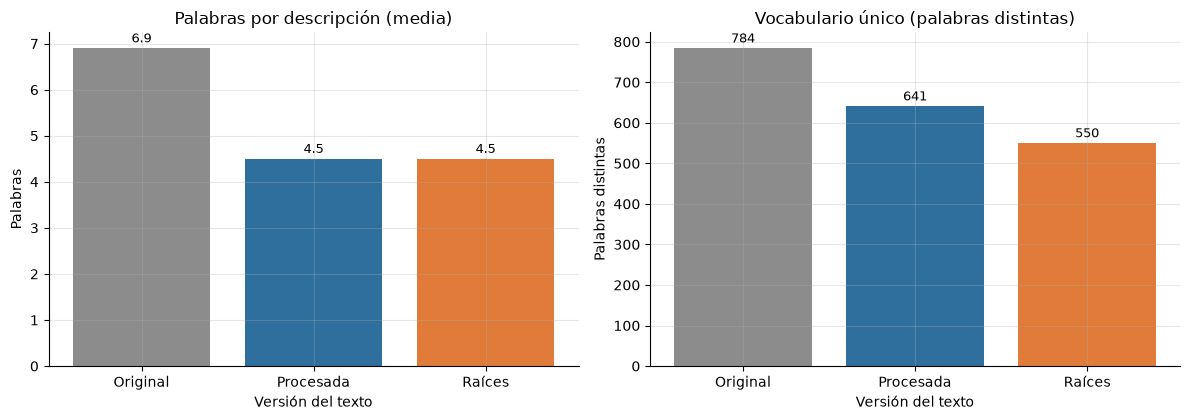

El vocabulario se redujo en 30% entre el texto original y las raíces.


In [87]:
# Versión "original": solo separar por espacios (sin limpiar). Se pasa a minúsculas para una comparación justa con las demás.
palabras_original = df["descripcion"].str.lower().str.split()

metricas = pd.DataFrame({
    "Versión": ["Original", "Procesada (limpia, sin palabras vacías)", "Raíces (stemming)"],
    "Caracteres por descripción (media)": [
        df["descripcion"].str.len().mean(),
        df["texto_proc"].str.len().mean(),
        df["raices"].apply(lambda r: len(" ".join(r))).mean()],
    "Palabras por descripción (media)": [
        palabras_original.apply(len).mean(),
        df["tokens"].apply(len).mean(),
        df["raices"].apply(len).mean()],
    "Total de palabras": [
        palabras_original.apply(len).sum(),
        df["tokens"].apply(len).sum(),
        df["raices"].apply(len).sum()],
    "Vocabulario único (palabras distintas)": [
        len(set(w for lista in palabras_original for w in lista)),
        len(set(w for lista in df["tokens"] for w in lista)),
        len(set(w for lista in df["raices"] for w in lista))],
}).round(1)
display(metricas)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.3))
colores = [GRIS, AZUL, NARANJA]
ejes[0].bar(["Original", "Procesada", "Raíces"], metricas["Palabras por descripción (media)"], color=colores)
ejes[0].set_title("Palabras por descripción (media)"); ejes[0].set_ylabel("Palabras"); ejes[0].set_xlabel("Versión del texto")
etiquetar(ejes[0])
ejes[1].bar(["Original", "Procesada", "Raíces"], metricas["Vocabulario único (palabras distintas)"], color=colores)
ejes[1].set_title("Vocabulario único (palabras distintas)"); ejes[1].set_ylabel("Palabras distintas"); ejes[1].set_xlabel("Versión del texto")
etiquetar(ejes[1])
plt.tight_layout(); plt.show()

reduccion = (1 - metricas.loc[2, "Vocabulario único (palabras distintas)"] / metricas.loc[0, "Vocabulario único (palabras distintas)"]) * 100
print(f"El vocabulario se redujo en {reduccion:.0f}% entre el texto original y las raíces.")

**Ejemplos concretos "antes → después"** (los 6 textos con mayor cambio de longitud):

In [88]:
df["cambio_longitud"] = df["descripcion"].str.len() - df["texto_proc"].str.len()
ejemplos = df.nlargest(6, "cambio_longitud")[["descripcion", "texto_proc"]].copy()
ejemplos["descripcion"] = ejemplos["descripcion"].str.replace(r"\s+", " ", regex=True).str[:130]
ejemplos.columns = ["Original", "Procesado"]
ejemplos.reset_index(drop=True)

,Original,Procesado
0,"Actualmente, se encuentra en su etapa inicial, enfocándose en la construcción de una i...",actualmente encuentra etapa inicial enfocandose construccion identidad marca captacion...
1,PAPU EARINGS ES UN EMPRENDIMIENTO DEDICADO A LA CREACIÓN DE ACCESORIOS PERSONALIZADOS ...,papu earings emprendimiento dedicado creacion accesorios personalizados porcelanicron ...
2,El emprendimiento se dedica a la producción y venta de galletas estilo New York y roll...,emprendimiento dedica produccion venta galletas estilo new york rollos canela ofrecien...
3,ArteSublime es una empresa dedicada a la personalización de productos a través de técn...,artesublime empresa dedicada personalizacion productos traves tecnicas sublimacion est...
4,Fabricación y venta de la réplica de la piedra del sapo en cerámica y pocillos en cerá...,fabricacion venta replica piedra sapo ceramica pocillos ceramica variedad fotos parque
5,WAYA STORE ES UNA APUESTA AL BORDADO HECHO A MANO SOBRE PRENDAS PARA QUE TODAS LAS MUJ...,waya store apuesta bordado hecho mano prendas mujeres reflejen creatividad amor propio...


**Lectura del resultado.** El preprocesamiento tuvo el efecto esperado:

* **Textos más compactos:** de 47,6 a **39,9 caracteres** por descripción, y de 6,9 a **4,5 palabras** (se eliminaron las palabras vacías).
* **Vocabulario más ordenado:** de **784 palabras distintas** en el texto original a **641** tras la limpieza (se unificaron mayúsculas, tildes y signos) y a **550** con raíces (se agruparon variantes como *artesanía/artesanías/artesanal*). Es una **reducción del 30 %** sin perder el significado principal.
* En los ejemplos se observa también que desaparecen conectores ("de", "y", "la"), signos y mayúsculas, y queda el contenido que describe el negocio.

### 5.7 Representaciones numéricas: Count, n-gramas y TF-IDF

**1. Qué se hace:** convertir el texto en **números**, porque los algoritmos solo trabajan con números. Usaremos tres técnicas:

| Técnica | Qué hace | Por qué se usa |
|---|---|---|
| **Count (frecuencia)** de palabras sueltas (*unigramas*) | Cuenta cuántas veces aparece cada palabra | La más simple e intuitiva: responde "¿qué palabras se usan más?" |
| **n-gramas (bigramas = pares de palabras)** | Cuenta pares consecutivos como "venta comidas" | Una palabra sola pierde contexto; el par captura **expresiones** ("productos artesanales", "tejidos crochet") |
| **TF-IDF** | Da más peso a las palabras **frecuentes en un texto pero poco comunes en el resto** | Las palabras más repetidas ("producción", "venta") están en casi todos los textos y no distinguen nada; TF-IDF **resalta lo que hace diferente a cada grupo** |

**2. Por qué estas tres:** se complementan. Count y n-gramas describen lo **más frecuente**; TF-IDF encuentra lo **más característico**.

**3. Herramienta:** `scikit-learn` (`CountVectorizer`, `TfidfVectorizer`).

#### Count: palabras y pares de palabras más frecuentes

,ANTES: sin preprocesar,veces,DESPUÉS: procesado,veces
0,de,270,elaboracion,55
1,y,175,venta,49
2,en,67,productos,38
3,venta,49,comercializacion,36
4,productos,37,produccion,23
5,elaboración,33,fabricacion,23
6,a,33,postres,20
7,para,22,crochet,17
8,elaboracion,22,artesanias,16
9,la,21,manualidades,14


,palabra,veces,par de palabras,veces
0,elaboracion,55,produccion comercializacion,16
1,venta,49,elaboracion venta,10
2,productos,38,comercializacion productos,10
3,comercializacion,36,tejidos crochet,6
4,fabricacion,23,elaboracion productos,6
5,produccion,23,fabricacion venta,5
6,postres,20,elaboracion comercializacion,4
7,crochet,17,comercializacion artesanias,4
8,artesanias,16,productos crochet,4
9,manualidades,14,crochet macrame,3


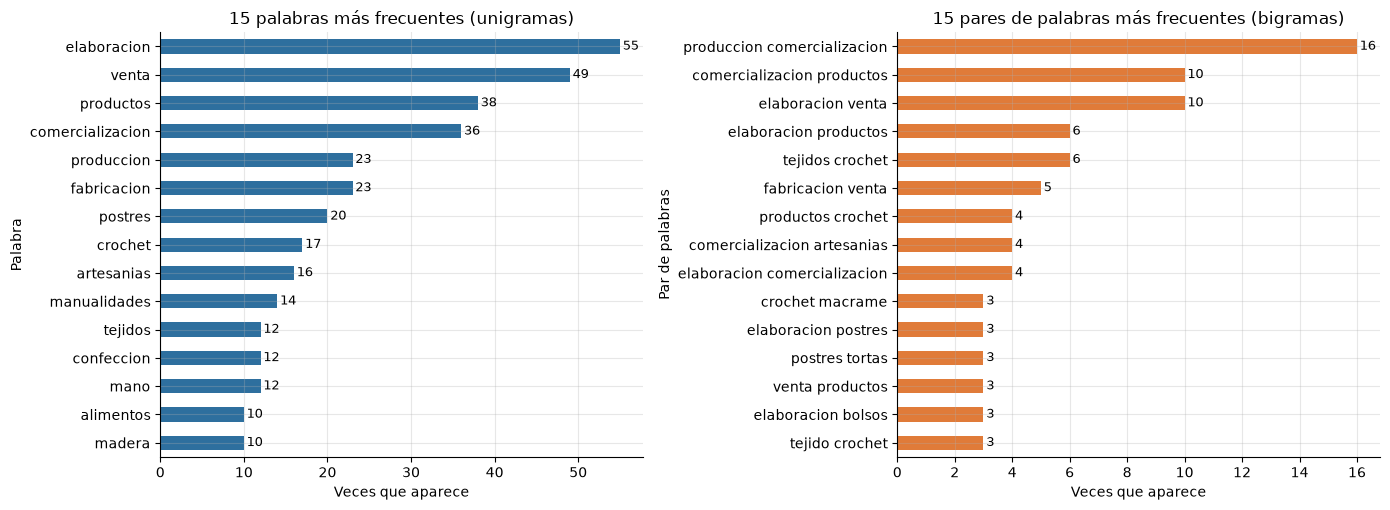

In [89]:
# ANTES -> DESPUÉS: las 10 palabras más contadas SIN preprocesar vs. con el texto procesado
sin_procesar = pd.Series([w for lista in df["descripcion"].str.lower().str.split() for w in lista]).value_counts().head(10)
procesado = pd.Series([w for lista in df["tokens"] for w in lista]).value_counts().head(10)
display(pd.DataFrame({"ANTES: sin preprocesar": sin_procesar.index, "veces": sin_procesar.values,
                      "DESPUÉS: procesado": procesado.index, "veces ": procesado.values}))

def top_frecuentes(textos, n_gramas, cuantos=15, min_docs=2):
    """Cuenta las expresiones más frecuentes. n_gramas=(1,1) -> palabras; (2,2) -> pares de palabras.
    min_docs=2 descarta expresiones que aparecen en un solo texto (casi siempre son nombres propios o errores)."""
    vectorizador = CountVectorizer(ngram_range=n_gramas, min_df=min_docs)
    matriz = vectorizador.fit_transform(textos)                 # matriz: filas = textos, columnas = palabras
    conteos = np.asarray(matriz.sum(axis=0)).ravel()            # sumar cada columna = total por palabra
    return pd.Series(conteos, index=vectorizador.get_feature_names_out()).sort_values(ascending=False).head(cuantos)

top_palabras = top_frecuentes(df["texto_proc"], (1, 1))
top_pares = top_frecuentes(df["texto_proc"], (2, 2))
display(pd.concat([top_palabras.rename_axis("palabra").reset_index(name="veces"),
                   top_pares.rename_axis("par de palabras").reset_index(name="veces ")], axis=1))

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.2))
top_palabras.sort_values().plot.barh(ax=ejes[0], color=AZUL)
etiquetar(ejes[0]); ejes[0].set_title("15 palabras más frecuentes (unigramas)")
ejes[0].set_xlabel("Veces que aparece"); ejes[0].set_ylabel("Palabra")

top_pares.sort_values().plot.barh(ax=ejes[1], color=NARANJA)
etiquetar(ejes[1]); ejes[1].set_title("15 pares de palabras más frecuentes (bigramas)")
ejes[1].set_xlabel("Veces que aparece"); ejes[1].set_ylabel("Par de palabras")
plt.tight_layout(); plt.show()

**Lectura del resultado.** (Las palabras aparecen sin tilde porque ese fue el paso de normalización.)

* Las palabras más frecuentes son **verbos de actividad**: *elaboración* (55), *venta* (49), *comercialización* (36), *fabricación* y *producción* (23 cada una). Los emprendedores describen **qué hacen con el producto** (lo elaboran, lo producen, lo venden).
* Aparecen también los **nichos concretos**: *postres* (20), *crochet* (17), *artesanías* (16), *manualidades* (14), *tejidos* (12) y *madera* (10).
* Los **pares de palabras** aportan contexto que una palabra sola no da: *producción comercialización* (16 veces; el modelo "hago y vendo"), *tejidos crochet* (6) y *elaboración postres* (3).
* Como las palabras "de actividad" aparecen en casi todos los textos, **no sirven para diferenciar sectores**; para eso usamos TF-IDF a continuación.

#### Nube de palabras

**1. Qué se hace:** dibujar una **nube de palabras** donde el tamaño de cada palabra es proporcional a su frecuencia.

**2. Por qué:** es un resumen visual inmediato, ideal para presentaciones. Sus límites: no muestra relaciones ni sentimientos, solo frecuencia; por eso la acompañamos de las barras y tablas.

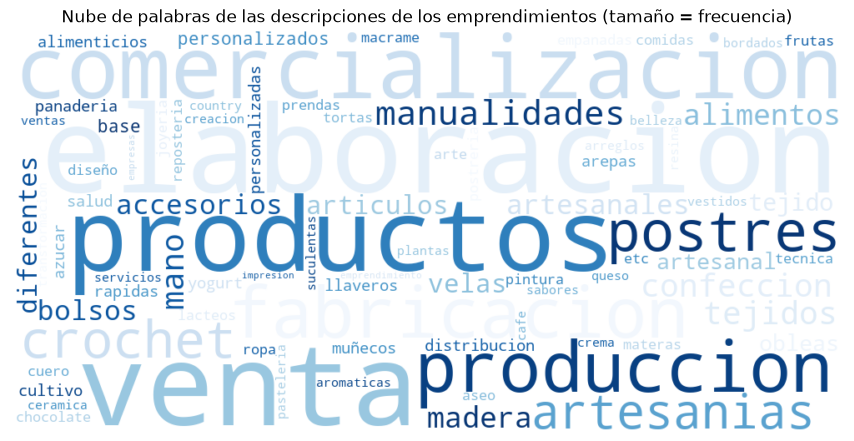

In [90]:
frecuencias = top_frecuentes(df["texto_proc"], (1, 1), cuantos=80, min_docs=2)

nube = WordCloud(width=1000, height=480, background_color="white", colormap="Blues",
                 max_words=80, random_state=1).generate_from_frequencies(frecuencias.to_dict())

plt.figure(figsize=(11, 5.2))
plt.imshow(nube, interpolation="bilinear")
plt.axis("off")
plt.title("Nube de palabras de las descripciones de los emprendimientos (tamaño = frecuencia)")
plt.show()

#### TF-IDF: ¿qué palabras caracterizan a cada sector?

**1. Qué se hace:** calcular TF-IDF sobre las descripciones y, para cada sector grande (15 o más emprendedores), listar las **palabras con mayor peso promedio**.

**2. Por qué:** así se responde "¿con qué palabras se describe cada sector?" sin que las palabras generales ("producción", "venta") tapen a las específicas ("crochet", "arepas", "jabones").

**Cómo leer la tabla:** el número es el peso TF-IDF promedio de esa palabra dentro del sector; **a mayor peso, más característica es del sector**.

In [91]:
tfidf = TfidfVectorizer(min_df=3, ngram_range=(1, 1))              # solo palabras que aparecen en 3+ descripciones
matriz_tfidf = tfidf.fit_transform(df["texto_proc"])
vocabulario = np.array(tfidf.get_feature_names_out())

filas = []
for sector in df["linea_grupo"].value_counts()[lambda s: s >= 15].index:
    posiciones = np.where(df["linea_grupo"] == sector)[0]
    peso_promedio = np.asarray(matriz_tfidf[posiciones].mean(axis=0)).ravel()      # peso promedio de cada palabra en el sector
    mejores = peso_promedio.argsort()[::-1][:6]                                     # las 6 de mayor peso
    filas.append({"Sector": sector,
                  "Emprendedores": len(posiciones),
                  "Palabras más características (peso TF-IDF)": ", ".join(f"{vocabulario[i]} ({peso_promedio[i]:.2f})" for i in mejores)})

pd.DataFrame(filas)

,Sector,Emprendedores,Palabras más características (peso TF-IDF)
0,Artesanías y manualidades,105,"artesanias (0.10), manualidades (0.09), crochet (0.08), elaboracion (0.08), fabricacio..."
1,Alimentos,100,"elaboracion (0.12), venta (0.11), postres (0.10), alimentos (0.08), productos (0.07), ..."
2,"Textil, confección y cuero",24,"confeccion (0.26), bolsos (0.11), calzado (0.10), elaboracion (0.08), marca (0.07), pr..."
3,Comercio,23,"venta (0.35), comercializacion (0.21), productos (0.12), salud (0.06), postreria (0.05..."
4,Servicios,20,"comercializacion (0.11), salud (0.10), productos (0.07), venta (0.07), personalizados ..."


**Lectura del resultado.** TF-IDF muestra qué distingue a cada sector:

* **Artesanías y manualidades:** *artesanías, manualidades, crochet*, es decir, trabajo manual y tejido.
* **Alimentos:** *postres, alimentos, elaboración*, con foco en repostería y comidas.
* **Textil, confección y cuero:** *confección* (peso muy alto, 0,26), *bolsos, calzado*.
* **Comercio:** *venta* y *comercialización* dominan: se describen por **lo que venden**, no por lo que producen.
* **Servicios:** *salud, personalizados*, mezcla de salud visual, publicidad y personalización de productos.

*Nota* como los sectores se asignaron en parte leyendo estas mismas descripciones, esta tabla sirve sobre todo para **comprobar que la agrupación es coherente** (las palabras características coinciden con el nombre del sector).

### 5.8 Análisis de sentimientos

**1. Qué se hace:** clasificar cada descripción como **Positiva, Neutra o Negativa** según las palabras que contiene.

**2. Método elegido: análisis por léxico (diccionario de palabras).** Se parte de dos listas: palabras que expresan **valoración positiva** (*calidad, creatividad, exclusivo, saludable...*) y palabras que expresan **valoración negativa** (*problema, dificultad, deficiente...*).

* A cada descripción se le suman +1 por cada palabra positiva y −1 por cada negativa.
* **Negaciones:** si la palabra anterior es "no", "sin", "nunca" o "ni", el signo se invierte ("**no** es de calidad" cuenta como negativo).
* **Resultado:** puntaje > 0 → **Positivo**; puntaje < 0 → **Negativo**; puntaje = 0 → **Neutro**.
* Se comparan **raíces** (no palabras exactas), así "creativo", "creativa" y "creatividad" cuentan igual.

**3. Por qué este método y no un modelo de inteligencia artificial:** es **transparente** (se puede explicar palabra por palabra, algo clave para presentarlo a públicos no técnicos), no necesita descargar modelos externos y es **adecuado para textos cortos y descriptivos**. Su limitación es que solo reconoce las palabras de la lista, y el diccionario fue elaborado por nosotros para este contexto (no es un diccionario académico validado).

**Expectativa realista:** las descripciones son **descriptivas** ("producción y venta de postres"), no opiniones. Por eso es esperable que **la gran mayoría sea neutra**; el sentimiento aparecerá sobre todo en los textos donde el emprendedor *se presenta* o *promociona* su negocio. Reportar esto con honestidad es parte del análisis.

In [92]:
# Diccionario de palabras con carga positiva o negativa (se compara por raíces)
# Solo se incluyen palabras de VALORACIÓN (opinión). Se dejaron fuera palabras que solo DESCRIBEN el producto
# (natural, saludable, tradicional, fresco...), porque "yogur natural" no expresa un sentimiento.
palabras_positivas = """excelente buena bueno calidad creativo creativa creatividad exclusivo exclusiva exclusividad original
perfecto perfectos beneficio beneficios innovador innovadora innovacion sostenible amor unico unica especial
hermoso hermosa elegante delicioso deliciosa rico ricos feliz disfrutar encanto confiable""".split()

palabras_negativas = """problema problemas dificultad dificultades malo mala deficiente escaso escasa falta crisis perdida
riesgo deterioro contaminante defectuoso informal incipiente""".split()

raices_positivas = {stemmer.stem(quitar_tildes(p)) for p in palabras_positivas}
raices_negativas = {stemmer.stem(quitar_tildes(p)) for p in palabras_negativas}
negadores = {"no", "sin", "nunca", "ni"}

def puntaje_sentimiento(tokens):
    """Suma +1 por palabra positiva y -1 por negativa; invierte el signo si la palabra anterior es una negación."""
    puntaje, encontradas = 0, []
    for i, palabra in enumerate(tokens):
        raiz = stemmer.stem(palabra)
        valor = 1 if raiz in raices_positivas else (-1 if raiz in raices_negativas else 0)
        if valor != 0:
            if i > 0 and tokens[i - 1] in negadores:       # negación -> se invierte
                valor = -valor
            puntaje += valor
            encontradas.append((palabra, valor))
    return puntaje, encontradas

resultados = df["tokens_todos"].apply(puntaje_sentimiento)    # usamos los tokens CON palabras vacías para poder ver las negaciones
df["puntaje_sentimiento"] = resultados.apply(lambda r: r[0])
df["palabras_con_sentimiento"] = resultados.apply(lambda r: r[1])
df["sentimiento"] = pd.cut(df["puntaje_sentimiento"], bins=[-100, -1, 0, 100], labels=["Negativo", "Neutro", "Positivo"])

# ANTES -> DESPUÉS del uso de raíces: ¿cuántas descripciones se detectan con palabras exactas vs. con raíces?
exactas = {quitar_tildes(p) for p in palabras_positivas + palabras_negativas}
con_exactas = df["tokens_todos"].apply(lambda toks: any(t in exactas for t in toks)).sum()
con_raices = (df["puntaje_sentimiento"] != 0).sum()
print(f"Descripciones con alguna palabra de sentimiento detectada -> solo palabras exactas: {con_exactas} | usando raíces: {con_raices}\n")

conteo_sent = df["sentimiento"].value_counts().reindex(["Positivo", "Neutro", "Negativo"])
print(pd.DataFrame({"descripciones": conteo_sent, "%": (conteo_sent / len(df) * 100).round(1)}))

Descripciones con alguna palabra de sentimiento detectada -> solo palabras exactas: 10 | usando raíces: 11

             descripciones     %
sentimiento                     
Positivo                11   3.7
Neutro                 284  96.3
Negativo                 0   0.0


**Visualización del sentimiento:** (a) cuántas descripciones hay de cada tipo y (b) las palabras que más aportaron a la clasificación.

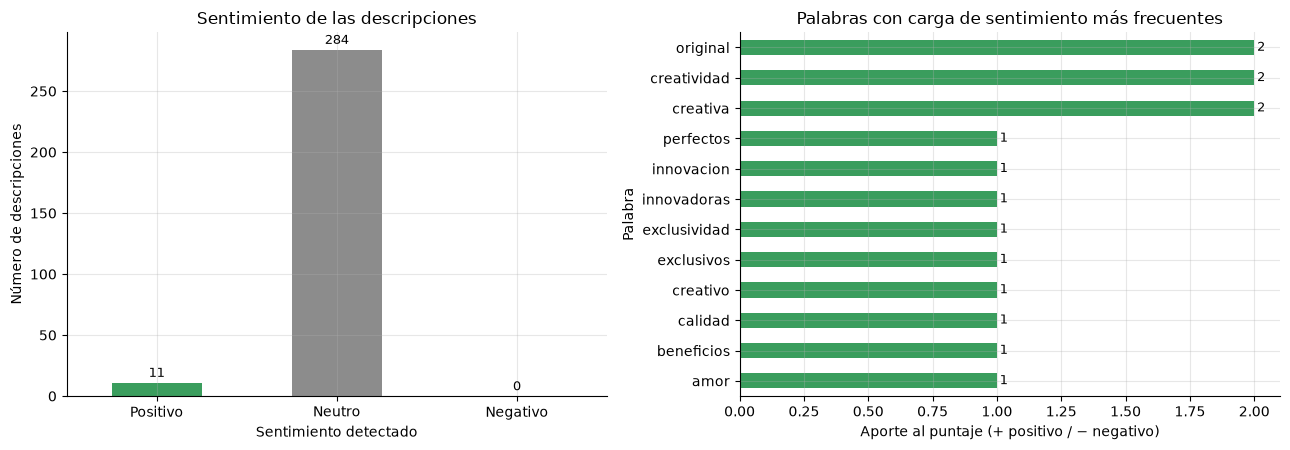

In [93]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.6))

# (a) Distribución del sentimiento
conteo_sent.plot.bar(ax=ejes[0], color=["#3A9D5D", GRIS, "#C8553D"], rot=0)
etiquetar(ejes[0])
ejes[0].set_title("Sentimiento de las descripciones")
ejes[0].set_xlabel("Sentimiento detectado"); ejes[0].set_ylabel("Número de descripciones")

# (b) Palabras que más aportaron (positivas en verde, negativas en rojo)
aportes = pd.Series([p for lista in df["palabras_con_sentimiento"] for p in lista], dtype=object)
if len(aportes) > 0:
    tabla_aportes = pd.DataFrame(aportes.tolist(), columns=["palabra", "valor"])
    top_aportes = tabla_aportes.groupby("palabra")["valor"].sum().sort_values().tail(12)
    colores_barra = ["#3A9D5D" if v > 0 else "#C8553D" for v in top_aportes.values]
    top_aportes.plot.barh(ax=ejes[1], color=colores_barra)
    etiquetar(ejes[1])
ejes[1].set_title("Palabras con carga de sentimiento más frecuentes")
ejes[1].set_xlabel("Aporte al puntaje (+ positivo / − negativo)"); ejes[1].set_ylabel("Palabra")

plt.tight_layout(); plt.show()

**Revisión manual (validación):** un análisis automático siempre debe revisarse a ojo. Aquí se muestran ejemplos de textos clasificados como positivos o negativos junto con las palabras que activaron la clasificación.

In [94]:
revision = df[df["sentimiento"] != "Neutro"][["descripcion", "sentimiento", "palabras_con_sentimiento"]].copy()
revision["descripcion"] = revision["descripcion"].str.replace(r"\s+", " ", regex=True).str[:140]
revision["palabras_con_sentimiento"] = revision["palabras_con_sentimiento"].apply(lambda l: ", ".join(f"{p} ({v:+d})" for p, v in l))
print(f"Descripciones no neutras: {len(revision)} de {len(df)}")
revision.head(12).reset_index(drop=True)

Descripciones no neutras: 11 de 295


,descripcion,sentimiento,palabras_con_sentimiento
0,TALLER CREATIVO BASADO EN EL DESARROLLO DE PRODUCTOS Y PIEZAS PUBLICITARIAS PARA EMPRE...,Positivo,creativo (+1)
1,TIENDA CREATIVA DE CROCHET Y COUNTRY,Positivo,creativa (+1)
2,REDISEÑAR PRENDAS CON DISEÑOS INNOVADORAS CON PRENDAS QUE NO SE VENDEN POR PASADAS DE ...,Positivo,innovadoras (+1)
3,WAYA STORE ES UNA APUESTA AL BORDADO HECHO A MANO SOBRE PRENDAS PARA QUE TODAS LAS MUJ...,Positivo,"creatividad (+1), amor (+1)"
4,ELABORACION DE EMPANADAS DE DIFERENTES SABORES E INNOVACION DE MASA,Positivo,innovacion (+1)
5,PAPU EARINGS ES UN EMPRENDIMIENTO DEDICADO A LA CREACIÓN DE ACCESORIOS PERSONALIZADOS ...,Positivo,"exclusivos (+1), creatividad (+1), perfectos (+1), original (+1)"
6,"Papelería creativa, personalizado de agendas, pines, camisetas, gorras, mugs, llaveros...",Positivo,creativa (+1)
7,Posicionamiento de productos de alta rotación que beneficios la salud y son de consumo...,Positivo,beneficios (+1)
8,"Creación de materas con diseño original, amigurumis y llaveros en técnica hama beads",Positivo,original (+1)
9,El emprendimiento se dedica a la producción y venta de galletas estilo New York y roll...,Positivo,calidad (+1)


In [95]:
# ¿El sentimiento cambia según el sector? (porcentaje dentro de cada sector)
sent_por_sector = pd.crosstab(df["linea_grupo"], df["sentimiento"], normalize="index").mul(100).round(1)
sent_por_sector["n"] = df["linea_grupo"].value_counts()
sent_por_sector.sort_values("n", ascending=False)

sentimiento,Neutro,Positivo,n
linea_grupo,,,
Artesanías y manualidades,95.2,4.8,105
Alimentos,98.0,2.0,100
"Textil, confección y cuero",91.7,8.3,24
Comercio,95.7,4.3,23
Servicios,95.0,5.0,20
"Aseo, belleza y cosméticos",100.0,0.0,11
Agropecuario,100.0,0.0,6
Industria y manufactura,100.0,0.0,6


**Lectura del resultado.**

* **El 96 % de las descripciones es neutro (284 de 295), el 4 % es positivo (11) y no hay ninguna negativa.** Es lo esperado: las descripciones son **fichas técnicas** del negocio ("producción y venta de postres"), no opiniones.
* El tono positivo aparece en los emprendedores que **se presentan o promocionan** su negocio con palabras como *creatividad, innovación, original, exclusivo, perfecto*. Un ejemplo es "diseños exclusivos que destacan por su creatividad".
* Por sector, los porcentajes positivos más altos (textil 8 %, servicios 5 %) se basan en **uno o dos textos**, así que no se interpretan como diferencias reales.

**Nota** el método solo detecta las palabras de la lista. Por ejemplo, un texto que dice *"a pesar de no haber generado aún ingresos significativos..."* (tono algo negativo) queda como neutro porque ninguna de esas palabras está en el diccionario. Por eso este análisis se presenta como una **medida orientativa del tono de presentación**, no como una evaluación de la satisfacción ni del éxito de los negocios.

## 6. Conclusiones orientadas a la decisión 

### Resumen en una frase
> Facatativá tiene una base **joven, femenina y de microempresas** (artesanías y alimentos), con **baja formalización** (casi la mitad no tiene ni RUT, ni Cámara de Comercio, ni página web). La formalización va de la mano con la generación de empleo, y existe una **brecha de género** en la consolidación de los negocios.

### Hallazgos clave

| # | Hallazgo | Evidencia |
|---|---|---|
| 1 | **Microempresas jóvenes y unipersonales.** | Mediana de 4,6 años de antigüedad; 54 % creado desde 2022; ≈ 80 % sin empleados. |
| 2 | **Dos sectores concentran el 70 % del emprendimiento.** | Artesanías y manualidades (35,6 %) y alimentos (33,9 %). |
| 3 | **Predominan las mujeres.** | 72 % de los inscritos. |
| 4 | **La formalización es baja.** | 48 % sin RUT, Cámara ni web; solo 34 % con Cámara de Comercio, 47 % con RUT y 11 % con página web. |
| 5 | **Formalizarse se asocia con emplear.** | Empleo en el 8 % de los informales vs. 58 % de los de formalización alta; 44 % de los que tienen Cámara emplean vs. 9 % de los que no (p < 0,001). |
| 6 | **Hay una brecha de género en la consolidación.** | Madurez mediana de 27,7 (mujeres) vs. 30,0 (hombres), p = 0,009; empleadoras: 17 % vs. 29 %. |
| 7 | **Más estudios no implican por sí solos más madurez.** | Mediana ≈ 30 desde bachiller hasta profesional. |
| 8 | **Las poblaciones vulnerables no muestran brecha de formalización.** | 0,84 vs. 0,93 puntos; p = 0,53. |
| 9 | **Las descripciones son neutras y técnicas.** | 96 % neutro, 4 % positivo, 0 % negativo; vocabulario centrado en *elaboración, venta, crochet, postres*. |

### Implicaciones para la toma de decisiones
* **Formalizar rinde:** como la formalización se asocia con más empleo, apoyar la formalización es también una **política de empleo local**.
* **Hay un "público cercano":** los **44 negocios con RUT pero sin Cámara de Comercio** son el grupo con menor distancia a formalizarse del todo.
* **Los sectores grandes pesan más:** artesanías y alimentos suman ~70 % de los inscritos; un programa dirigido a ellos llega a la mayoría.
* **La brecha de género importa por escala:** al ser mujeres el 72 % de la base, cualquier mejora en su consolidación mueve el resultado general.

### Recomendaciones prácticas
1. **Ruta de formalización por etapas** (RUT → Cámara de Comercio → presencia digital), empezando por los 44 negocios con RUT sin Cámara, con acompañamiento en trámites y costos.
2. **Programa de apoyo con enfoque de género:** formación, redes de contactos y acceso a financiación para mujeres emprendedoras, con horarios compatibles con labores de cuidado, para cerrar la brecha de empleo y consolidación.
3. **Capacitación en ventas digitales** para artesanías y alimentos (solo 11 % tiene página web): redes sociales, catálogos digitales y venta en línea.
4. **Atención particular al sector Comercio**, que es el menos formalizado entre los grandes (22 % con Cámara) pese a ser quien vende.
5. **Estrategia diferenciada para la zona rural** (solo 20 emprendimientos, con formalización mucho menor: 0,45 vs. 0,94 urbana, dato descriptivo que debe confirmarse con más casos).
6. **Mejorar el formulario de inscripción** (esta es una conclusión del propio proceso de limpieza):
   * Usar **listas desplegables** para género, tipo de documento, formación y línea económica (hoy hay 5, 8, 43 y 80 escrituras distintas).
   * **Validar fechas** (impedir años imposibles como 1905) y evitar inscripciones duplicadas.
   * Añadir **rangos de ingresos o ventas** para poder medir el impacto económico real.
   * Añadir una **pregunta abierta sobre "principal dificultad"**: las descripciones actuales son neutras, y una pregunta así permitiría un análisis de sentimientos con verdadero valor.
7. **Repetir el análisis cada año** con el mismo código para medir si las acciones mejoran la formalización, y **hacer seguimiento a la cohorte 2024** (70 negocios) para ver cuántos sobreviven y se formalizan.

### Lo que este análisis NO permite concluir
* **No es representativo de todo Facatativá:** solo describe a quienes se inscribieron.
* **No demuestra causalidad:** que la formalización se asocie con más empleo no prueba que formalizar *cause* más empleo.
* **No mide ingresos:** el índice de madurez es un indicador construido, no una medida económica.

## 7. Documentación técnica

### 7.1 Resumen del flujo de trabajo (Parte 1: etapas 1 a 4 · Parte 2: etapas 5 a 7)

| Etapa | Qué se hizo | Herramientas |
|---|---|---|
| Carga | Lectura del Excel, nombres cortos, copia de trabajo | `pandas` |
| Exploración | Tipos, faltantes, estadística descriptiva, histogramas y cajas | `pandas`, `scipy`, `matplotlib` |
| Limpieza | Normalización de texto, agrupación por palabras clave, tratamiento de fechas imposibles, atípicos, faltantes y duplicados | `pandas`, `re`, `unicodedata` |
| Transformación | Antigüedad, índice de formalización, tamaño, grupos y índice de madurez | `pandas`, `numpy` |
| Visualización | Barras, histogramas, diagramas de caja, mapa de calor | `matplotlib` |
| Inferencia | Mann-Whitney, Chi-cuadrado, Spearman | `scipy.stats` |
| Texto | Limpieza, tokenización, stopwords, stemming, Count, bigramas, TF-IDF, nube de palabras, sentimiento por léxico | `re`, `nltk`, `scikit-learn`, `wordcloud` |

### 7.2 Limitaciones del análisis 

1. **Muestra no representativa de todo el municipio:** son quienes **se inscribieron** en la Secretaría; los emprendedores no inscritos (muchos informales) no están. Los resultados describen a los inscritos, no a todo Facatativá.
2. **Tamaño pequeño (295 registros tras la limpieza):** los sectores con pocos casos no permiten conclusiones firmes; por eso se filtraron los grupos con menos de 10 casos.
3. **Sin ingresos ni ventas:** el índice de madurez es un **indicador construido** con pesos definidos por criterio, no una medida económica. Con otros pesos los resultados cambiarían ligeramente.
4. **Datos autodeclarados:** las respuestas las escribieron las propias personas, sin verificación (por ejemplo, la existencia real del RUT o de la inscripción en Cámara de Comercio).
5. **Clasificaciones por palabras clave:** la agrupación de formación, sector y población pudo asignar mal algún caso ambiguo (se dejaron los dudosos como "Sin dato" u "Otros").
6. **Sentimiento por léxico:** depende de un diccionario hecho a mano y de textos descriptivos; no detecta ironía ni palabras fuera de la lista.
7. **Los valores p** indican si hay evidencia de diferencia, no su importancia práctica, y no prueban causalidad.

### 7.3 Datos de salida
Al final se guarda un segundo archivo, `emprendedores_resultados_texto.csv`, con el texto procesado y el sentimiento de cada descripción. La tabla limpia de la Parte 1 (`emprendedores_limpio.csv`) **no se modifica**.

In [96]:
salida = df[["item", "nombre", "linea_grupo", "descripcion", "texto_proc", "puntaje_sentimiento", "sentimiento"]]
salida.to_csv("emprendedores_resultados_texto.csv", index=False, encoding="utf-8-sig")   # utf-8-sig: las tildes se ven bien en Excel
print("Archivo guardado: emprendedores_resultados_texto.csv con", salida.shape[0], "filas y", salida.shape[1], "columnas")

Archivo guardado: emprendedores_resultados_texto.csv con 295 filas y 7 columnas
